<p align="center">
  <img src="assets/hero_proje.svg" width="100%" alt="Gün 52 — Titanik: LightGBM merkezli uçtan uca proje">
</p>

<p align="center">
  <img src="https://img.shields.io/badge/G%C3%BCn-52-0B3A52?style=for-the-badge" alt="Gün 52">
  <img src="https://img.shields.io/badge/Konu-LightGBM_(Proje)-E5A100?style=for-the-badge" alt="Konu">
  <img src="https://img.shields.io/badge/Veri-Titanik_891_yolcu-0EA5C6?style=for-the-badge" alt="Veri">
  <img src="https://img.shields.io/badge/Algoritma-27%2B_taban-D1495B?style=for-the-badge" alt="Algoritma">
  <img src="https://img.shields.io/badge/Seviye-Orta-16A34A?style=for-the-badge" alt="Seviye">
</p>

<table>
<tr><td width="25%" valign="top" align="center"><h3>🛡️</h3><b>Sızıntısız</b><br><br>Aile ve bilet grupları<br><b>aynı tarafta</b> kalır<br><br></td><td width="25%" valign="top" align="center"><h3>🏁</h3><b>Büyük yarış</b><br><br>27 algoritma,<br><b>aynı parkur, aynı katlar</b><br><br></td><td width="25%" valign="top" align="center"><h3>🍃</h3><b>LightGBM yakından</b><br><br>Düğmeleri <b>tek tek</b> çevirip ölçeriz<br><br></td><td width="25%" valign="top" align="center"><h3>⚖️</h3><b>Adalet denetimi</b><br><br>Kim için <b>daha çok yanılıyoruz?</b><br><br></td></tr>
</table>

<table><tr><td>

<img src="assets/etiket_hedef.svg" height="34" alt="Hedefler">

**Bu notebook'un sonunda şunları yapabiliyor olacaksınız:**

- 🚢 Titanik yolcularının hayatta kalmasını tahmin eden **uçtan uca** bir sınıflandırma projesi yürütmek
- 🧾 Eksik veriyi, etiket sütunlarını ve sorunlu sütunları **karar defteriyle** yönetmek
- 🛡️ **Hedef sızıntısını** ve **aile/bilet sızıntısını** deneyle ölçmek, grup bazlı doğrulama kurmak
- 🏁 **27 algoritmayı (+ taban)** aynı sızıntısız boru hattında yarıştırmak ve farkın **şans mı gerçek mi** olduğuna bakmak
- 🍃 LightGBM düğmelerini (yaprak sayısı, öğrenme hızı, örnekleme, düzenleme, `boosting_type`…) küçük veride **tek tek** çevirmek
- 🎛️ LightGBM, XGBoost ve CatBoost'u **rastgele arama** ile ayarlayıp taze katlarda doğrulamak
- 🔍 Özellik önemini (split, gain, permütasyon, **TreeSHAP**) ve **ablasyonu** yorumlamak
- ⚖️ Modeli **segmentlere** (cinsiyet, sınıf, yaş…) bölerek **adalet** açısından denetlemek
- 🎯 **Kalibrasyon, eşik ve bütçeli seçim** ile sonucu karara bağlamak
- 💾 Modeli kaydedip **ayrı bir süreçte** yeniden yükleyerek test etmek

</td></tr></table>

<p align="center">
  <img src="assets/yol_haritasi_proje.svg" width="100%" alt="Proje yol haritası: 16 bölüm">
</p>

### 🧭 Hızlı Erişim

| # | Bölüm | # | Bölüm |
|:-:|:--|:-:|:--|
| 1 | [Kurulum](#p1) | 9 | [LightGBM yakından](#p9) |
| 2 | [Senaryo ve başarı ölçütleri](#p2) | 10 | [Hiperparametre ayarı](#p10) |
| 3 | [Veri kalitesi ve karar defteri](#p3) | 11 | [Özellik önemi ve ablasyon](#p11) |
| 4 | [Keşifsel analiz (test kilitli)](#p4) | 12 | [Final model](#p12) |
| 5 | [Dürüst bölme: sızıntı deneyleri](#p5) | 13 | [Adalet ve segment denetimi](#p13) |
| 6 | [Özellik mühendisliği ve boru hattı](#p6) | 14 | [Kalibrasyon ve karar](#p14) |
| 7 | [Büyük yarış (27 algoritma + taban)](#p7) | 15 | [Model kaydı ve yeniden yükleme](#p15) |
| 8 | [Yarışın röntgeni](#p8) | 16 | [Özet, quiz, ödevler, kaynakça](#p16) |

<a id="p1"></a>

<p align="center">
  <img src="assets/proje_01.svg" width="100%" alt="Bölüm 1 · Kurulum">
</p>

Kütüphaneleri, renkleri ve ortak yardımcıları tek hücrede topluyoruz. Özellik üretimi ve boru hattı kurucuları, `joblib` ile kaydedilebilmesi için ayrı bir dosyada (`titanik_yardimci.py`).

In [1]:
# ── Kütüphaneler ─────────────────────────────────────────────
import os, time, warnings, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import xgboost
import sklearn
from IPython.display import Image, Markdown, display
from matplotlib.animation import FuncAnimation, PillowWriter
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score, f1_score
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

from titanik_yardimci import veri_oku, OzellikUretici, SAYISAL, KATEGORIK

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"
RANDOM_STATE = 42
FIG_DIR = Path("outputs/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
REP_DIR = Path("outputs/reports"); REP_DIR.mkdir(parents=True, exist_ok=True)

# Renk paleti (Titanik teması: okyanus + altın)
RENK = {"altin": "#E5A100", "mavi": "#2B6CB0", "cyan": "#0E9AA7", "yesil": "#2E9E6B", "pembe": "#D1495B",
        "mor": "#6C5CE7", "turuncu": "#E8833A", "gri": "#8A94A6", "koyu": "#1F2A44"}
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight", "axes.titleweight": "bold",
                     "axes.titlesize": 13, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False, "grid.alpha": 0.25})


def kaydet(fig, ad):
    """Grafiği outputs/figures altına PNG olarak kaydeder."""
    fig.savefig(FIG_DIR / f"{ad}.png")
    print(f"💾 Kaydedildi → outputs/figures/{ad}.png")


def gif_kaydet(kare_ciz, n_kare, ad, figsize=(8, 4.4), fps=6):
    """kare_ciz(i, ax_listesi) fonksiyonuyla animasyon üretir, GIF olarak kaydeder ve gösterir."""
    fig = plt.figure(figsize=figsize)
    def guncelle(i):
        fig.clear(); kare_ciz(i, fig)
        try: fig.tight_layout()
        except Exception: pass
        return []
    anim = FuncAnimation(fig, guncelle, frames=n_kare, blit=False)
    yol = FIG_DIR / f"{ad}.gif"
    anim.save(yol, writer=PillowWriter(fps=fps), dpi=80)
    plt.close(fig)
    print(f"🎞️ Animasyon → {yol}")
    display(Image(filename=str(yol)))


def rapor_kaydet(df, ad, index=True):
    """Tabloyu outputs/reports altına CSV olarak yazar."""
    df.to_csv(REP_DIR / f"{ad}.csv", index=index, encoding="utf-8-sig")
    print(f"📄 Rapor → outputs/reports/{ad}.csv")

from itertools import chain
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (brier_score_loss, confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
                             average_precision_score, classification_report)
from sklearn.inspection import permutation_importance
from titanik_yardimci import hazirlik_standart, lgb_dogal, KolonSec, unvan_cikar

print("lightgbm", lgb.__version__, "| xgboost", xgboost.__version__, "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

lightgbm 4.7.0 | xgboost 3.4.1 | scikit-learn 1.9.1 | pandas 3.0.5


<a id="p2"></a>

<p align="center">
  <img src="assets/proje_02.svg" width="100%" alt="Bölüm 2 · Senaryo">
</p>

### 🚢 2.1 · Senaryo

Titanik'in yolcu listesi elimizde. Soru: **bir yolcunun hayatta kalıp kalmadığını, yolculuk öncesi bilinen bilgilerden (bilet, kabin, yaş, aile, unvan…) tahmin edebilir miyiz?** Bu bir **tarihsel analiz** ve yöntem çalışmasıdır; amaç gerçek kişiler hakkında karar vermek değil, **dürüst bir makine öğrenmesi sürecini** baştan sona görmektir.

<p align="center">
  <img src="assets/diyagram_proje_akisi.svg" width="100%" alt="Proje akışı">
</p>

### 📚 2.2 · Veri Seti

`22-titanic.csv`: 891 yolcu, 12 sütun. Bu, yaygın kullanılan Kaggle eğitim kümesidir (Kaggle, 2012); yolcuların tamamı değil, bir **örneklemdir**. Tarihsel bağlam için bkz. Frey, Savage ve Torgler (2011): "kadınlar ve çocuklar önce" normu ile sınıf farkları hayatta kalmayı güçlü biçimde etkilemiştir (Hall, 1986).

### 📏 2.3 · Başarı Ölçütleri

| Ölçüt | Ne söyler? | Neden? |
|:--|:--|:--|
| **ROC-AUC** | Kurtulanı kurtulamayandan ayırma gücü | Eşikten bağımsız, ana sıralama ölçütü |
| **Log-loss** | Olasılıkların kalitesi | Aşırı özgüveni cezalandırır |
| **Doğruluk, F1** | Sınıf kararlarının kalitesi | Okunması kolay; **taban oranı** (%38,4 kurtuldu) ile birlikte okunmalı |
| **Brier** | Olasılık hatasının karesi | Kalibrasyon bölümünde |

<table><tr><td>

<img src="assets/etiket_etik.svg" height="34" alt="Etik not">

`Sex`, `Pclass` gibi sütunlar **tarihsel gerçeklerdir**; bir modelin bunları kullanması, bugün gerçek insanlar hakkında cinsiyete veya sınıfa dayalı karar vermeyi **meşrulaştırmaz**. 13. bölümde modelin **hangi gruplar için daha çok yanıldığını** ölçeceğiz.

</td></tr></table>

<a id="p3"></a>

<p align="center">
  <img src="assets/proje_03.svg" width="100%" alt="Bölüm 3 · Veri kalitesi">
</p>

### 🧬 3.1 · İlk Bakış: Eksikler, Tekrarlar, Tuhaflıklar

In [2]:
ham = veri_oku()
print("Satır, sütun:", ham.shape)
display(ham.head(3))
kalite = pd.DataFrame({"tür": ham.dtypes.astype(str), "eksik": ham.isna().sum(), "eksik %": (ham.isna().mean() * 100).round(1), "tekil değer": ham.nunique()})
display(kalite)
rapor_kaydet(kalite, "01_veri_kalitesi")
print("\nTekrarlayan PassengerId:", ham["PassengerId"].duplicated().sum(), "| tamamen aynı satır:", ham.drop(columns="PassengerId").duplicated().sum())
print("Ücreti 0 olan yolcu:", int((ham["Fare"] == 0).sum()), "| aynı bileti paylaşan yolcu oranı: %.1f%%" % (100 * (ham["Ticket"].map(ham["Ticket"].value_counts()) > 1).mean()))
print("Hayatta kalma oranı (taban):", round(ham["Survived"].mean(), 3))

Satır, sütun: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


,tür,eksik,eksik %,tekil değer
PassengerId,int64,0,0.0,891
Survived,int64,0,0.0,2
Pclass,int64,0,0.0,3
Name,str,0,0.0,891
Sex,str,0,0.0,2
Age,float64,177,19.9,88
SibSp,int64,0,0.0,7
Parch,int64,0,0.0,7
Ticket,str,0,0.0,681
Fare,float64,0,0.0,248


📄 Rapor → outputs/reports/01_veri_kalitesi.csv

Tekrarlayan PassengerId: 0 | tamamen aynı satır: 0
Ücreti 0 olan yolcu: 15 | aynı bileti paylaşan yolcu oranı: 38.6%
Hayatta kalma oranı (taban): 0.384


### 🧾 3.2 · Karar Defteri

Her sütun için **ne yaptığımızı ve nedenini** yazıyoruz. Eksik değerlerin **nasıl** dolduruluşu önemlidir: doldurma değerleri yalnızca **eğitim katından** öğrenilir (5. bölümde bunun neden şart olduğunu görüyoruz).

In [3]:
karar = pd.DataFrame([
    ("PassengerId", "Çıkarıldı", "Kimlik numarası; tahmin gücü yok, ezber yoluna açık"),
    ("Survived", "Hedef", "1 = kurtuldu"),
    ("Pclass, Sex, SibSp, Parch, Fare, Embarked", "Kullanıldı", "Ham sütunlar (Embarked'de 2 eksik: eğitimdeki en sık değer)"),
    ("Age", "Kullanıldı + YasEksik bayrağı", "%19,9 eksik; eksik olması bilgi taşıyabilir; doldurma yalnızca eğitim katının medyanıyla"),
    ("Name", "Unvan (Mr, Mrs, Miss, Master, Diger) üretildi", "Ham ad modele verilmez; unvan yaş ve medeni durumu özetler"),
    ("Ticket", "BiletGrubu ve KisiBasiUcret üretildi", "Aynı bileti paylaşanlar çoğunlukla aile/grup; bilet no kendisi çıkarıldı. Aynı zamanda grup anahtarı (5. bölüm)"),
    ("Cabin", "KabinVar bayrağı ve Guverte (ilk harf)", "%77 eksik; kabin kaydının olması sınıfla ilişkili"),
], columns=["Sütun", "Karar", "Gerekçe"])
display(karar.style.hide(axis="index"))
rapor_kaydet(karar, "02_karar_defteri", index=False)

Sütun,Karar,Gerekçe
PassengerId,Çıkarıldı,"Kimlik numarası; tahmin gücü yok, ezber yoluna açık"
Survived,Hedef,1 = kurtuldu
"Pclass, Sex, SibSp, Parch, Fare, Embarked",Kullanıldı,Ham sütunlar (Embarked'de 2 eksik: eğitimdeki en sık değer)
Age,Kullanıldı + YasEksik bayrağı,"%19,9 eksik; eksik olması bilgi taşıyabilir; doldurma yalnızca eğitim katının medyanıyla"
Name,"Unvan (Mr, Mrs, Miss, Master, Diger) üretildi",Ham ad modele verilmez; unvan yaş ve medeni durumu özetler
Ticket,BiletGrubu ve KisiBasiUcret üretildi,Aynı bileti paylaşanlar çoğunlukla aile/grup; bilet no kendisi çıkarıldı. Aynı zamanda grup anahtarı (5. bölüm)
Cabin,KabinVar bayrağı ve Guverte (ilk harf),%77 eksik; kabin kaydının olması sınıfla ilişkili


📄 Rapor → outputs/reports/02_karar_defteri.csv


<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="Dikkat">

`Cabin`'in dolu olması kısmen **sonradan kaydedilmiş** olabilir: kabin bilgisi kurtulanlardan sonradan toplanmış olabilir. Bu, hedefin **dolaylı sızıntısı** riskidir. 6. bölümde `KabinVar`'ı kaldırıp skorun ne kadar değiştiğini ölçeceğiz ve karar ona göre verilecek.

</td></tr></table>

<a id="p4"></a>

<p align="center">
  <img src="assets/proje_04.svg" width="100%" alt="Bölüm 4 · Keşif">
</p>

### 🔒 4.1 · Önce Test Setini Kilitleyelim

Keşfe başlamadan **%20'lik bir test seti** ayırıp bir kenara koyuyoruz. Bundan sonra yapılan her inceleme, seçim ve ayar **yalnızca eğitim kısmına** bakar; test seti 12. bölümde **tek seferde** açılır.

In [4]:
MANIFEST = ham["Ticket"].value_counts().to_dict()    # yolcu listesi (hedef değil): bilet başına kaç kişi
tr_idx, te_idx = train_test_split(np.arange(len(ham)), test_size=0.20, stratify=ham["Survived"], random_state=RANDOM_STATE)
Xtr, Xte = ham.iloc[tr_idx].reset_index(drop=True), ham.iloc[te_idx].reset_index(drop=True)
ytr, yte = Xtr["Survived"].to_numpy(), Xte["Survived"].to_numpy()
gruplar = Xtr["Ticket"].to_numpy()                   # aynı bilet = aynı grup
print(f"Eğitim: {len(Xtr)} yolcu (kurtulan %{ytr.mean()*100:.1f}) | Test: {len(Xte)} yolcu (kurtulan %{yte.mean()*100:.1f})")
ortak_bilet = Xte["Ticket"].isin(set(Xtr["Ticket"])).mean()
print(f"Test yolcularının %{ortak_bilet*100:.1f}'i eğitimdeki biriyle aynı bileti paylaşıyor (grup sızıntısı riski, 5. bölüm)")

Eğitim: 712 yolcu (kurtulan %38.3) | Test: 179 yolcu (kurtulan %38.5)
Test yolcularının %37.4'i eğitimdeki biriyle aynı bileti paylaşıyor (grup sızıntısı riski, 5. bölüm)


### 🔍 4.2 · Kim Kurtuldu? (yalnızca eğitim kısmı)

💾 Kaydedildi → outputs/figures/01_eda_genel.png


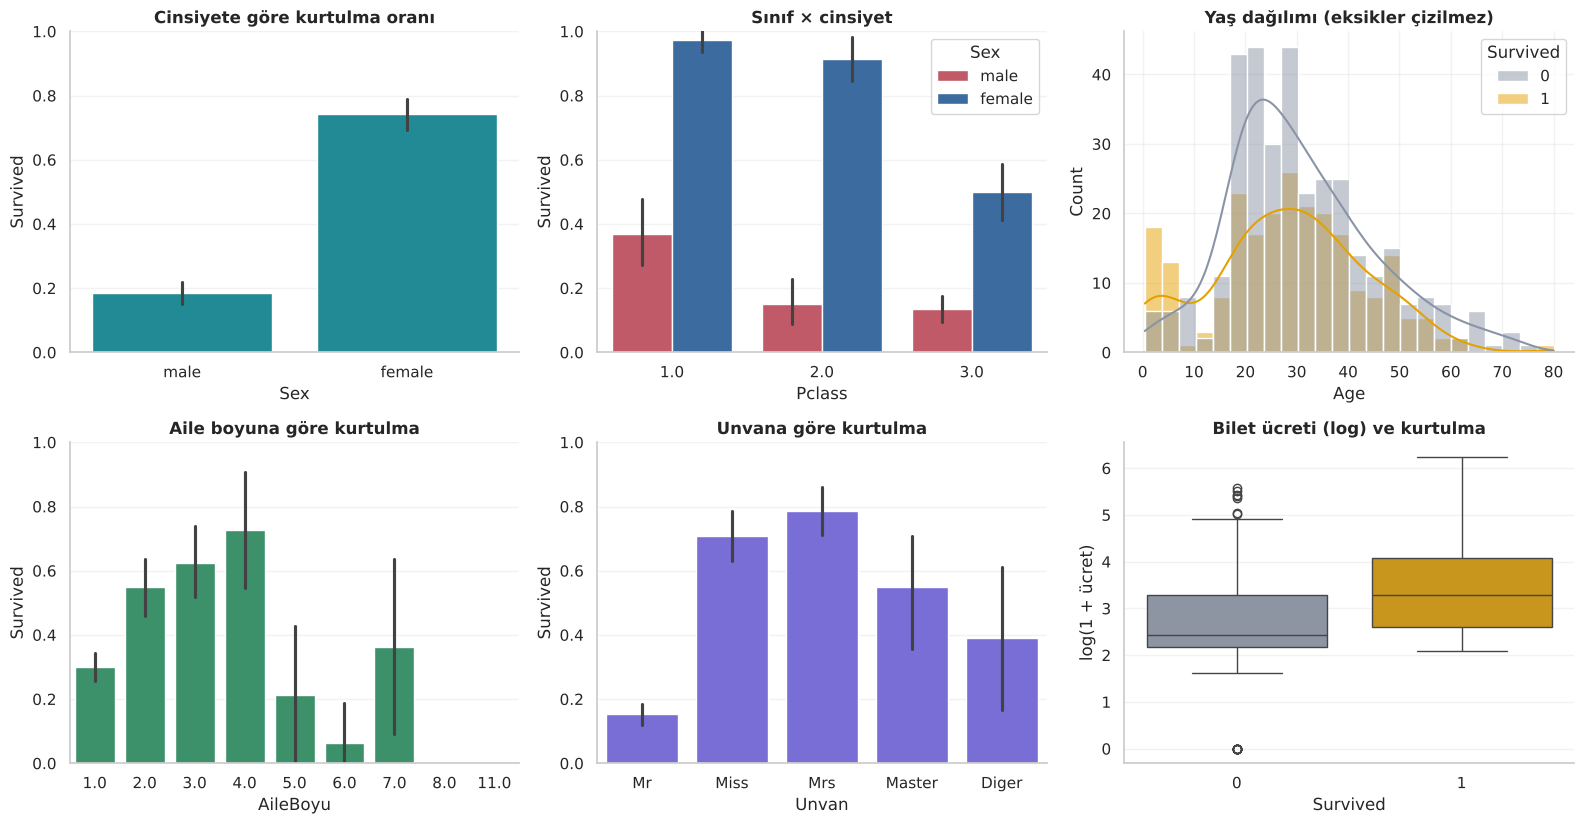

In [5]:
E = OzellikUretici(bilet_sayilari=MANIFEST).fit_transform(Xtr)
E["Survived"] = ytr
fig, ax = plt.subplots(2, 3, figsize=(16, 8.4))
sns.barplot(data=E, x="Sex", y="Survived", ax=ax[0, 0], color=RENK["cyan"]); ax[0, 0].set(title="Cinsiyete göre kurtulma oranı", ylim=(0, 1))
sns.barplot(data=E, x="Pclass", y="Survived", hue="Sex", ax=ax[0, 1], palette=[RENK["pembe"], RENK["mavi"]]); ax[0, 1].set(title="Sınıf × cinsiyet", ylim=(0, 1))
sns.histplot(data=E, x="Age", hue="Survived", bins=24, kde=True, ax=ax[0, 2], palette=[RENK["gri"], RENK["altin"]]); ax[0, 2].set(title="Yaş dağılımı (eksikler çizilmez)")
sns.barplot(data=E, x="AileBoyu", y="Survived", ax=ax[1, 0], color=RENK["yesil"]); ax[1, 0].set(title="Aile boyuna göre kurtulma", ylim=(0, 1))
sns.barplot(data=E, x="Unvan", y="Survived", ax=ax[1, 1], color=RENK["mor"], order=["Mr", "Miss", "Mrs", "Master", "Diger"]); ax[1, 1].set(title="Unvana göre kurtulma", ylim=(0, 1))
sns.boxplot(data=E, x="Survived", y=np.log1p(E["Fare"]), ax=ax[1, 2], palette=[RENK["gri"], RENK["altin"]]); ax[1, 2].set(title="Bilet ücreti (log) ve kurtulma", ylabel="log(1 + ücret)")
plt.tight_layout(); kaydet(fig, "01_eda_genel"); plt.show()

### 🔗 4.3 · İlişkiler: Korelasyon ve Karşılıklı Bilgi

**Karşılıklı bilgi**, doğrusal olmayan ilişkileri de yakalar. (Eksik yaşlar bu hesap için medyanla dolduruldu.)

💾 Kaydedildi → outputs/figures/02_iliskiler.png


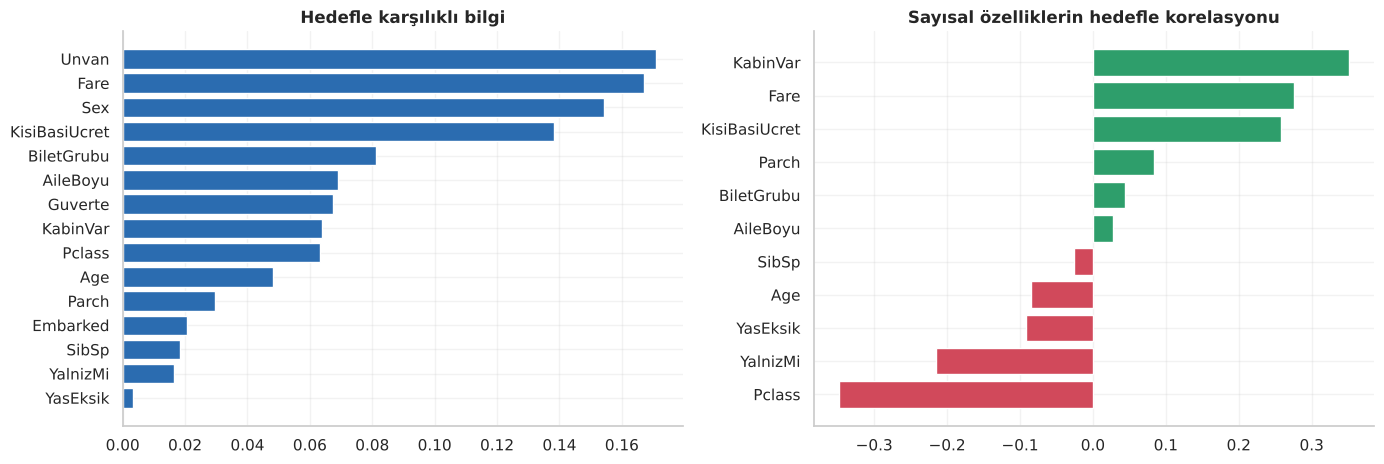

📄 Rapor → outputs/reports/03_karsilikli_bilgi.csv


In [6]:
from sklearn.feature_selection import mutual_info_classif
E2 = E.drop(columns="Survived").copy()
E2["Age"] = E2["Age"].fillna(E2["Age"].median())
for c in KATEGORIK: E2[c] = E2[c].astype("category").cat.codes
mi = pd.Series(mutual_info_classif(E2, ytr, discrete_features=[c in KATEGORIK for c in E2.columns], random_state=RANDOM_STATE), index=E2.columns).sort_values(ascending=False)
kor = E.drop(columns=["Survived"] + KATEGORIK).corrwith(E["Survived"]).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].barh(mi.index[::-1], mi.values[::-1], color=RENK["mavi"]); ax[0].set(title="Hedefle karşılıklı bilgi")
ax[1].barh(kor.index, kor.values, color=[RENK["pembe"] if v < 0 else RENK["yesil"] for v in kor.values]); ax[1].set(title="Sayısal özelliklerin hedefle korelasyonu")
plt.tight_layout(); kaydet(fig, "02_iliskiler"); plt.show()
rapor_kaydet(mi.rename("karşılıklı bilgi").to_frame(), "03_karsilikli_bilgi")

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Cinsiyet ve unvan en güçlü işaretler; sınıf ve ücret onları izliyor. `Fare` ile `Pclass` birbirine bağlı olduğundan bilgi **tekrarlıdır**. Aile boyu **doğrusal olmayan** bir ilişki gösterir (yalnız olanlar ve çok kalabalık aileler daha riskli): ağaç tabanlı modellerin sevdiği bir durum.

</td></tr></table>

<a id="p5"></a>

<p align="center">
  <img src="assets/proje_05.svg" width="100%" alt="Bölüm 5 · Dürüst bölme">
</p>

Doğrulamanın amacı **gelecekteki bilinmeyen yolcular** için skoru tahmin etmektir. İki tuzak var:

<p align="center">
  <img src="assets/diyagram_sizinti.svg" width="100%" alt="Aile sızıntısı">
</p>

1. **Hedef sızıntısı:** tahmin anında elde olmayan (ya da hedeften türeyen) bilgiyi özellik yapmak.
2. **Aile/bilet sızıntısı:** aynı grubun üyeleri hem eğitimde hem doğrulamada olunca model **akrabayı ezberler** (Roberts vd., 2017; Kaufman vd., 2012).

### 🧪 5.1 · Deney: Aile Sağ Kalım Oranı Özelliği

Popüler bir hile: *"Aynı bileti paylaşan **diğer yolcuların kurtulma oranı**"* özelliği. Hesabı tüm etiketlerle yaparsak doğrulama katındaki yolcunun **akrabalarının cevabını** da kullanmış oluruz. Doğru yol: oranı yalnızca **eğitim katının etiketlerinden** hesaplamak (ve test yolcusu yeni bir grupsa özellik boş kalır).

,Doğruluk,ROC-AUC
AileOrani yok (referans),0.8287,0.8902
AileOrani: etiket sızdırılmış (rastgele katlar),0.8449,0.9057
AileOrani: yalnızca eğitim etiketleri (rastgele katlar),0.8406,0.9019
AileOrani: yalnızca eğitim etiketleri (grup katları),0.8026,0.8557


📄 Rapor → outputs/reports/04_sizinti_aile_orani.csv
💾 Kaydedildi → outputs/figures/03_sizinti_aile_orani.png


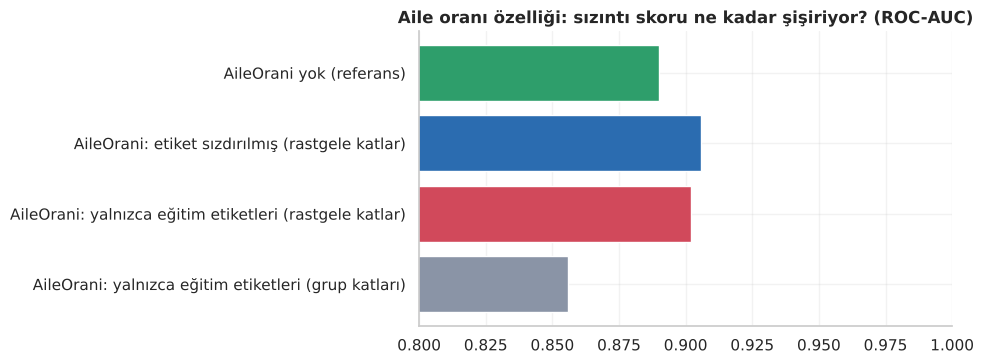

In [7]:
CV_RASTGELE = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=7).split(Xtr, ytr))
CV_GRUP = list(chain.from_iterable(StratifiedGroupKFold(5, shuffle=True, random_state=s).split(Xtr, ytr, gruplar) for s in (11, 12)))

def oran(bilet, d_s, kendi_y=None):
    """Aynı biletteki diğer yolcuların kurtulma oranı. d_s: bilet → (toplam, adet). kendi_y verilirse kendisi çıkarılır; kimse kalmazsa NaN."""
    s = bilet.map(d_s["sum"]).fillna(0).to_numpy(); c = bilet.map(d_s["count"]).fillna(0).to_numpy()
    if kendi_y is not None: s = s - kendi_y; c = c - 1
    return np.where(c > 0, s / np.maximum(c, 1), np.nan)

def skor_ozellikli(bolmeler, sizdir):
    acc, auc = [], []
    for e, v in bolmeler:
        Xe, Xv = Xtr.iloc[e], Xtr.iloc[v]
        te = lgb_dogal(MANIFEST, verbosity=-1)[:-1].fit(Xe, ytr[e]); A = te.transform(Xe); V = te.transform(Xv)
        if sizdir:   # SIZINTI: doğrulama katındaki akrabaların etiketleri de kullanılıyor (kendisi hariç)
            tum_b = pd.concat([Xe["Ticket"], Xv["Ticket"]]); tum_y = np.r_[ytr[e], ytr[v]]
            d_s = pd.DataFrame({"b": tum_b.to_numpy(), "y": tum_y}).groupby("b")["y"].agg(["sum", "count"])
            A["AileOrani"] = oran(Xe["Ticket"], d_s, ytr[e]); V["AileOrani"] = oran(Xv["Ticket"], d_s, ytr[v])
        else:        # DÜRÜST: yalnızca eğitim katının etiketleri
            d_s = pd.DataFrame({"b": Xe["Ticket"].to_numpy(), "y": ytr[e]}).groupby("b")["y"].agg(["sum", "count"])
            A["AileOrani"] = oran(Xe["Ticket"], d_s, ytr[e]); V["AileOrani"] = oran(Xv["Ticket"], d_s)
        m = LGBMClassifier(n_estimators=150, learning_rate=0.05, num_leaves=8, min_child_samples=10, verbosity=-1, random_state=RANDOM_STATE, n_jobs=4).fit(A, ytr[e])
        p = m.predict_proba(V)[:, 1]
        acc.append(accuracy_score(ytr[v], p > 0.5)); auc.append(roc_auc_score(ytr[v], p))
    return np.mean(acc), np.mean(auc)

def skor_ozelliksiz(bolmeler):
    r = cross_validate(lgb_dogal(MANIFEST, verbosity=-1, n_estimators=150, learning_rate=0.05, num_leaves=8, min_child_samples=10, random_state=RANDOM_STATE, n_jobs=1),
                       Xtr, ytr, cv=bolmeler, scoring={"acc": "accuracy", "auc": "roc_auc"}, n_jobs=4)
    return r["test_acc"].mean(), r["test_auc"].mean()

sizinti = pd.DataFrame({
    "AileOrani yok (referans)": skor_ozelliksiz(CV_RASTGELE),
    "AileOrani: etiket sızdırılmış (rastgele katlar)": skor_ozellikli(CV_RASTGELE, sizdir=True),
    "AileOrani: yalnızca eğitim etiketleri (rastgele katlar)": skor_ozellikli(CV_RASTGELE, sizdir=False),
    "AileOrani: yalnızca eğitim etiketleri (grup katları)": skor_ozellikli(CV_GRUP, sizdir=False),
}, index=["Doğruluk", "ROC-AUC"]).T
display(sizinti.round(4)); rapor_kaydet(sizinti, "04_sizinti_aile_orani")
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(sizinti.index[::-1], sizinti["ROC-AUC"].values[::-1], color=[RENK["yesil"], RENK["mavi"], RENK["pembe"], RENK["gri"]][::-1]); ax.set_xlim(0.8, 1.0)
ax.set(title="Aile oranı özelliği: sızıntı skoru ne kadar şişiriyor? (ROC-AUC)"); plt.tight_layout(); kaydet(fig, "03_sizinti_aile_orani"); plt.show()

In [8]:
ref, sz, dur_r, dur_g = sizinti["ROC-AUC"].to_numpy()
display(Markdown(f"**Okuma:** etiket sızdırılınca AUC referansa göre **{sz - ref:+.3f}**, dürüst (yalnızca eğitim etiketleri) sürümde **{dur_r - ref:+.3f}** değişti; grup katlarında aynı özellik **{dur_g:.3f}** AUC verdi. Bu veride sızıntının doğrudan etkisi küçük, ama **özelliğin kendisi** üretimde kullanılamaz: yeni bir yolcu listesinde akrabaların sonuçları **bilinmez**. Bu yüzden `AileOrani` modele **alınmıyor**; yalnızca yolcu listesinden bilinen `BiletGrubu` (grup büyüklüğü) aday özellik olarak kalıyor."))

**Okuma:** etiket sızdırılınca AUC referansa göre **+0.016**, dürüst (yalnızca eğitim etiketleri) sürümde **+0.012** değişti; grup katlarında aynı özellik **0.856** AUC verdi. Bu veride sızıntının doğrudan etkisi küçük, ama **özelliğin kendisi** üretimde kullanılamaz: yeni bir yolcu listesinde akrabaların sonuçları **bilinmez**. Bu yüzden `AileOrani` modele **alınmıyor**; yalnızca yolcu listesinden bilinen `BiletGrubu` (grup büyüklüğü) aday özellik olarak kalıyor.

### 🧪 5.2 · Deney: Rastgele Katlar mı, Grup Katları mı?

Aynı model, iki doğrulama düzeni: rastgele katlarda bilet grubu üyeleri iki tarafa dağılabilir; **grup katlarında** aynı bilet **tek bir tarafta** kalır.

In [9]:
temel = lgb_dogal(MANIFEST, verbosity=-1, n_estimators=150, learning_rate=0.05, num_leaves=8, min_child_samples=10, random_state=RANDOM_STATE, n_jobs=1)
SK = {"acc": "accuracy", "auc": "roc_auc", "f1": "f1"}
satir = []
for ad, bol in [("Rastgele katlar", CV_RASTGELE), ("Grup (bilet) katları", CV_GRUP)]:
    r = cross_validate(temel, Xtr, ytr, cv=bol, scoring=SK, n_jobs=4)
    satir.append({"Düzen": ad, "Doğruluk": r["test_acc"].mean(), "F1": r["test_f1"].mean(), "ROC-AUC": r["test_auc"].mean(), "Doğruluk std": r["test_acc"].std()})
duzen = pd.DataFrame(satir).set_index("Düzen"); display(duzen.round(4)); rapor_kaydet(duzen, "05_rastgele_vs_grup")
fark = duzen.loc["Rastgele katlar", "Doğruluk"] - duzen.loc["Grup (bilet) katları", "Doğruluk"]
display(Markdown(f"**Sonuç:** rastgele katlar, grup katlarına göre doğruluğu **{fark:+.3f}** farkla gösteriyor (fold std ≈ {duzen['Doğruluk std'].mean():.3f}). Bu projede model seçimi **grup katlarıyla** yapılacak."))

,Doğruluk,F1,ROC-AUC,Doğruluk std
Düzen,,,,
Rastgele katlar,0.8287,0.7634,0.8902,0.0261
Grup (bilet) katları,0.8159,0.7427,0.8456,0.0239


📄 Rapor → outputs/reports/05_rastgele_vs_grup.csv


**Sonuç:** rastgele katlar, grup katlarına göre doğruluğu **+0.013** farkla gösteriyor (fold std ≈ 0.025). Bu projede model seçimi **grup katlarıyla** yapılacak.

<a id="p6"></a>

<p align="center">
  <img src="assets/proje_06.svg" width="100%" alt="Bölüm 6 · Özellik mühendisliği">
</p>

### 🛠️ 6.1 · Boru Hattı (Pipeline)

Her modele **aynı sızıntısız boru hattı** giriyor:

`ham tablo → özellik üretimi (unvan, aile boyu, bilet grubu…) → [eksik doldurma + ölçekleme] ve [mod ile doldurma + tek-sıcak] → model`

Doldurma ve ölçekleme değerleri **yalnızca eğitim katında** öğrenilir. LightGBM için ayrıca eksik değeri ve kategoriyi **doğal** işleyen bir sürüm var.

In [10]:
hz = hazirlik_standart(MANIFEST).fit(Xtr, ytr)
cikti = hz.transform(Xtr)
print("Standart boru hattı çıktısı (tüm özelliklerle):", cikti.shape, "→ 11 sayısal + tek-sıcak kategorik sütunlar")
print("Eksik değer kaldı mı?", bool(np.isnan(cikti).any()))
ad_listesi = hz.named_steps["donustur"].get_feature_names_out()
print("İlk 12 sütun:", list(ad_listesi[:12]))

Standart boru hattı çıktısı (tüm özelliklerle): (712, 31) → 11 sayısal + tek-sıcak kategorik sütunlar
Eksik değer kaldı mı? False
İlk 12 sütun: ['sayisal__Pclass', 'sayisal__Age', 'sayisal__SibSp', 'sayisal__Parch', 'sayisal__Fare', 'sayisal__AileBoyu', 'sayisal__YalnizMi', 'sayisal__BiletGrubu', 'sayisal__KisiBasiUcret', 'sayisal__YasEksik', 'sayisal__KabinVar', 'kategorik__Sex_female']


### 🧪 6.2 · Deney: Hangi Özellik Grupları İşe Yarıyor?

LightGBM (doğal kategori) ile özellik gruplarını **adım adım** ekleyerek **grup katlarında** ölçüyoruz.

,val_logloss,tr_logloss,AUC,Doğruluk,Doğruluk std,Özellik sayısı
1) Ham 7 sütun,0.4393,0.2522,0.8625,0.8145,0.0281,7
2) + Unvan,0.4349,0.2501,0.8651,0.8131,0.0257,8
"3) + Aile (AileBoyu, YalnizMi)",0.4362,0.2447,0.8641,0.8188,0.0239,10
"4) + Bilet (BiletGrubu, KisiBasiUcret)",0.4558,0.2261,0.8540,0.8103,0.0178,12
"5) + Güverte, YasEksik, KabinVar (tümü)",0.4563,0.2234,0.8535,0.8153,0.0185,15


📄 Rapor → outputs/reports/06_ozellik_adimlari.csv


,AUC
Tümü,0.8535
"KabinVar, Guverte olmadan",0.8544


💾 Kaydedildi → outputs/figures/04_ozellik_adimlari.png


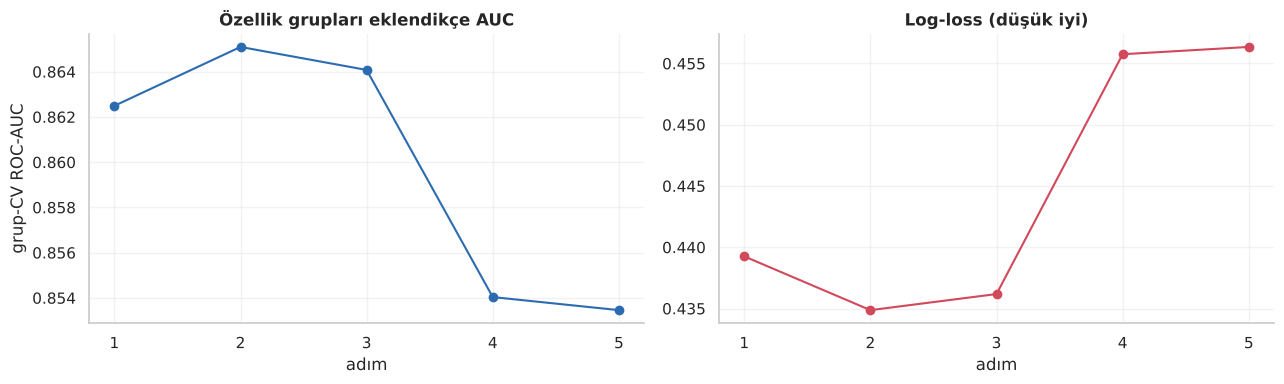

In [11]:
LGB_TEMEL = dict(n_estimators=200, learning_rate=0.05, num_leaves=8, min_child_samples=10, subsample=0.8, subsample_freq=1,
                 colsample_bytree=0.8, reg_lambda=1.0, verbosity=-1, random_state=RANDOM_STATE, n_jobs=1)
SK4 = {"ll": lambda e, X, y: -log_loss(y, e.predict_proba(X)[:, 1]), "auc": "roc_auc", "acc": "accuracy"}

SECILI = None   # 6.2 deneyinden sonra seçilecek özellik listesi (None = tümü)

def cv_lgb(cv=CV_GRUP, tut="varsayilan", at=None, **kw):
    tut = SECILI if (isinstance(tut, str) and tut == "varsayilan") else tut
    prm = dict(LGB_TEMEL); prm.update(kw)
    r = cross_validate(lgb_dogal(MANIFEST, tut=tut, at=at, **prm), Xtr, ytr, cv=cv, scoring=SK4, return_train_score=True, n_jobs=4)
    return {"val_logloss": -r["test_ll"].mean(), "tr_logloss": -r["train_ll"].mean(), "AUC": r["test_auc"].mean(), "Doğruluk": r["test_acc"].mean(), "Doğruluk std": r["test_acc"].std()}

HAM7 = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
adimlar = {"1) Ham 7 sütun": HAM7, "2) + Unvan": HAM7 + ["Unvan"], "3) + Aile (AileBoyu, YalnizMi)": HAM7 + ["Unvan", "AileBoyu", "YalnizMi"],
           "4) + Bilet (BiletGrubu, KisiBasiUcret)": HAM7 + ["Unvan", "AileBoyu", "YalnizMi", "BiletGrubu", "KisiBasiUcret"],
           "5) + Güverte, YasEksik, KabinVar (tümü)": HAM7 + ["Unvan", "AileBoyu", "YalnizMi", "BiletGrubu", "KisiBasiUcret", "Guverte", "YasEksik", "KabinVar"]}
ozel = pd.DataFrame({ad: cv_lgb(tut=k) for ad, k in adimlar.items()}).T
ozel["Özellik sayısı"] = [len(v) for v in adimlar.values()]
display(ozel.round(4)); rapor_kaydet(ozel, "06_ozellik_adimlari")
kabin = pd.Series({"Tümü": cv_lgb()["AUC"], "KabinVar, Guverte olmadan": cv_lgb(at=["KabinVar", "Guverte"])["AUC"]})
display(kabin.rename("AUC").to_frame().round(4))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(range(1, 6), ozel["AUC"], "o-", color=RENK["mavi"]); ax[0].set(title="Özellik grupları eklendikçe AUC", xlabel="adım", ylabel="grup-CV ROC-AUC"); ax[0].set_xticks(range(1, 6))
ax[1].plot(range(1, 6), ozel["val_logloss"], "o-", color=RENK["pembe"]); ax[1].set(title="Log-loss (düşük iyi)", xlabel="adım"); ax[1].set_xticks(range(1, 6))
plt.tight_layout(); kaydet(fig, "04_ozellik_adimlari"); plt.show()

In [12]:
# Seçim kuralı (sonuçları görmeden yazıldı): grup-CV log-loss'u en düşük özellik kümesi seçilir.
en_iyi_adim = ozel["val_logloss"].idxmin()
SECILI = adimlar[en_iyi_adim]
display(Markdown(f"**Seçilen özellik kümesi:** «{en_iyi_adim}» ({len(SECILI)} özellik): `{', '.join(SECILI)}`. "
                 f"Fark çoğu adımda fold standart sapmasının ({ozel['Doğruluk std'].mean():.3f}) içinde; yani **sadeleşmek bedava**. "
                 f"Seçilmeyenler (ör. `KabinVar`, `Guverte`) hem kazandırmadı hem **sonradan kaydedilmiş olma** riski taşıyordu."))

**Seçilen özellik kümesi:** «2) + Unvan» (8 özellik): `Pclass, Sex, Age, SibSp, Parch, Fare, Embarked, Unvan`. Fark çoğu adımda fold standart sapmasının (0.023) içinde; yani **sadeleşmek bedava**. Seçilmeyenler (ör. `KabinVar`, `Guverte`) hem kazandırmadı hem **sonradan kaydedilmiş olma** riski taşıyordu.

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Eklenen her özellik skoru yükseltmiyor: bazı gruplar grup-CV'de **eğitim log-loss'unu düşürüp doğrulama log-loss'unu yükseltiyor** (ezber işareti). Küçük veride **az ama sağlam** özellik, çok ama gürültülü özellikten iyidir. Bundan sonra **bütün algoritmalar** seçilen küme ile çalışır.

</td></tr></table>

<a id="p7"></a>

<p align="center">
  <img src="assets/proje_07.svg" width="100%" alt="Bölüm 7 · Büyük yarış">
</p>

### 🏁 7.1 · Yarışçılar

**27 algoritma + 1 taban** aynı boru hattında, **aynı grup katlarında** (10 kat: 2 tekrar × 5 kat, aynı bilet hep aynı tarafta) yarışıyor. Hiçbirine ayrıcalık yok: varsayılana yakın ayarlar, aynı girdi. LightGBM için ek olarak **doğal kategori** sürümü de koşuyor.

| Aile | Algoritmalar |
|:--|:--|
| Taban | En sık sınıfı söyle |
| Doğrusal | Lojistik regresyon, Ridge, SGD, Perceptron, Pasif-Agresif, Doğrusal SVM, LDA |
| Mesafe / olasılık | KNN, Gauss Naif Bayes, QDA, Gauss süreci |
| Çekirdek | RBF-SVM |
| Tek ağaç | Karar ağacı, Ekstra ağaç |
| Torbalama | Rastgele orman, Ekstra ağaçlar, Bagging |
| Boosting | AdaBoost, Gradient Boosting, HistGradientBoosting, **XGBoost**, **LightGBM**, CatBoost |
| Sinir ağı | MLP |
| Topluluk | Oylama (soft), Yığın (stacking) |

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier, Perceptron, PassiveAggressiveClassifier
from sklearn.svm import LinearSVC, SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF, ConstantKernel
from sklearn.tree import DecisionTreeClassifier, ExtraTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, BaggingClassifier, AdaBoostClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier, VotingClassifier, StackingClassifier)
from sklearn.neural_network import MLPClassifier
from catboost import CatBoostClassifier

R = RANDOM_STATE
def std(m): return Pipeline([("hz", hazirlik_standart(MANIFEST, SECILI)), ("m", m)])
def lgb_d(**kw): return lgb_dogal(MANIFEST, tut=SECILI, **kw)

def ll_skor(e, X, y):
    try: return -log_loss(y, e.predict_proba(X)[:, 1])
    except Exception: return np.nan
SKOR = {"acc": "accuracy", "f1": "f1", "auc": "roc_auc", "ll": ll_skor}
CV_TAZE = list(chain.from_iterable(StratifiedGroupKFold(5, shuffle=True, random_state=s).split(Xtr, ytr, gruplar) for s in (21, 22)))

yarisci = {
    "Taban: en sık sınıf": ("Taban", std(DummyClassifier(strategy="prior"))),
    "Lojistik regresyon": ("Doğrusal", std(LogisticRegression(max_iter=1000, random_state=R))),
    "Ridge sınıflandırıcı": ("Doğrusal", std(RidgeClassifier(random_state=R))),
    "SGD (log-loss)": ("Doğrusal", std(SGDClassifier(loss="log_loss", random_state=R))),
    "Perceptron": ("Doğrusal", std(Perceptron(random_state=R))),
    "Pasif-agresif": ("Doğrusal", std(PassiveAggressiveClassifier(random_state=R))),
    "Doğrusal SVM": ("Doğrusal", std(LinearSVC(random_state=R, max_iter=5000))),
    "LDA": ("Doğrusal", std(LinearDiscriminantAnalysis())),
    "KNN (k=15)": ("Mesafe/olasılık", std(KNeighborsClassifier(n_neighbors=15))),
    "Gauss Naif Bayes": ("Mesafe/olasılık", std(GaussianNB())),
    "QDA": ("Mesafe/olasılık", std(QuadraticDiscriminantAnalysis(reg_param=0.9))),
    "Gauss süreci": ("Mesafe/olasılık", std(GaussianProcessClassifier(kernel=ConstantKernel(1.0) * RBF(1.0), random_state=R))),
    "RBF-SVM": ("Çekirdek", std(SVC(random_state=R))),
    "Karar ağacı (derinlik 4)": ("Tek ağaç", std(DecisionTreeClassifier(max_depth=4, random_state=R))),
    "Ekstra ağaç (tek)": ("Tek ağaç", std(ExtraTreeClassifier(max_depth=6, random_state=R))),
    "Rastgele orman": ("Torbalama", std(RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=R, n_jobs=1))),
    "Ekstra ağaçlar": ("Torbalama", std(ExtraTreesClassifier(n_estimators=300, min_samples_leaf=3, random_state=R, n_jobs=1))),
    "Bagging (ağaç)": ("Torbalama", std(BaggingClassifier(n_estimators=100, random_state=R, n_jobs=1))),
    "AdaBoost": ("Boosting", std(AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=R))),
    "Gradient Boosting": ("Boosting", std(GradientBoostingClassifier(random_state=R))),
    "HistGradientBoosting": ("Boosting", std(HistGradientBoostingClassifier(random_state=R))),
    "XGBoost": ("Boosting", std(XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8, verbosity=0, random_state=R, n_jobs=1))),
    "LightGBM (varsayılan, ortak boru hattı)": ("Boosting", std(LGBMClassifier(verbosity=-1, random_state=R, n_jobs=1))),
    "LightGBM (doğal kategori, hafif ayar)": ("Boosting", lgb_d(**LGB_TEMEL)),
    "CatBoost": ("Boosting", std(CatBoostClassifier(iterations=300, learning_rate=0.05, depth=4, verbose=0, random_seed=R, thread_count=1, allow_writing_files=False))),
    "MLP (sinir ağı)": ("Sinir ağı", std(MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-2, max_iter=800, random_state=R))),
    "Oylama (LR + RF + LightGBM)": ("Topluluk", std(VotingClassifier([("lr", LogisticRegression(max_iter=1000)), ("rf", RandomForestClassifier(n_estimators=200, min_samples_leaf=3, random_state=R)),
                                                              ("lgb", LGBMClassifier(n_estimators=150, learning_rate=0.05, num_leaves=8, verbosity=-1, random_state=R, n_jobs=1))], voting="soft"))),
    "Yığın (RF + LightGBM + LR → LR)": ("Topluluk", std(StackingClassifier([("rf", RandomForestClassifier(n_estimators=150, min_samples_leaf=3, random_state=R)),
                                                               ("lgb", LGBMClassifier(n_estimators=150, learning_rate=0.05, num_leaves=8, verbosity=-1, random_state=R, n_jobs=1)),
                                                               ("lr", LogisticRegression(max_iter=1000))], final_estimator=LogisticRegression(max_iter=1000), cv=3))),
}
print(f"Yarışçı sayısı: {len(yarisci)} (taban hariç {len(yarisci) - 1})")

Yarışçı sayısı: 28 (taban hariç 27)


### 🏎️ 7.2 · Yarışı Koşalım

Her algoritma **10 katta** değerlendirilir. Ölçütler: doğruluk, F1, ROC-AUC, log-loss (olasılık üretemeyenler için boş), eğitim doğruluğu (ezber göstergesi) ve süre.

In [14]:
def yaris_kos(adlar, cv, model_sozlugu=None):
    model_sozlugu = model_sozlugu or yarisci
    sonuc = []
    for ad in adlar:
        aile, m = model_sozlugu[ad]
        t0 = time.perf_counter()
        r = cross_validate(m, Xtr, ytr, cv=cv, scoring=SKOR, return_train_score=True, n_jobs=4, error_score=np.nan)
        sonuc.append({"Algoritma": ad, "Aile": aile, "Doğruluk": np.nanmean(r["test_acc"]), "Doğruluk std": np.nanstd(r["test_acc"]), "F1": np.nanmean(r["test_f1"]),
                      "ROC-AUC": np.nanmean(r["test_auc"]), "AUC std": np.nanstd(r["test_auc"]), "Log-loss": -np.nanmean(r["test_ll"]) if not np.all(np.isnan(r["test_ll"])) else np.nan,
                      "Eğitim doğruluğu": np.nanmean(r["train_acc"]), "Süre (sn)": time.perf_counter() - t0})
    return pd.DataFrame(sonuc).set_index("Algoritma")

yaris = yaris_kos(list(yarisci), CV_GRUP).sort_values("ROC-AUC", ascending=False)
yaris["Sıra (AUC)"] = np.arange(1, len(yaris) + 1)
display(yaris.drop(columns=["AUC std"]).round(4))
rapor_kaydet(yaris, "07_yaris_grup_cv")
alg_sayisi = len(yaris) - 1
print(f"\n✅ {alg_sayisi} algoritma + taban koşuldu.")

,Aile,Doğruluk,Doğruluk std,F1,ROC-AUC,Log-loss,Eğitim doğruluğu,Süre (sn),Sıra (AUC)
Algoritma,,,,,,,,,
Oylama (LR + RF + LightGBM),Topluluk,0.8202,0.0276,0.7510,0.8735,0.4198,0.8834,1.0665,1
Yığın (RF + LightGBM + LR → LR),Topluluk,0.8202,0.0259,0.7514,0.8717,0.4217,0.8768,2.1878,2
AdaBoost,Boosting,0.8019,0.0395,0.7426,0.8695,0.5616,0.8200,1.1732,3
Rastgele orman,Torbalama,0.8131,0.0215,0.7338,0.8692,0.4294,0.8957,1.2933,4
"LightGBM (doğal kategori, hafif ayar)",Boosting,0.8131,0.0257,0.7435,0.8651,0.4349,0.9091,0.3143,5
XGBoost,Boosting,0.8103,0.0278,0.7392,0.8645,0.4381,0.9080,0.3784,6
Lojistik regresyon,Doğrusal,0.8174,0.0301,0.7531,0.8634,0.4329,0.8285,0.2344,7
Ridge sınıflandırıcı,Doğrusal,0.8167,0.0344,0.7527,0.8626,NaN,0.8276,0.1757,8
LDA,Doğrusal,0.8167,0.0360,0.7533,0.8620,0.4564,0.8274,0.2331,9


📄 Rapor → outputs/reports/07_yaris_grup_cv.csv

✅ 27 algoritma + taban koşuldu.


### 📊 7.3 · Yarışın Görseli

💾 Kaydedildi → outputs/figures/05_buyuk_yaris.png


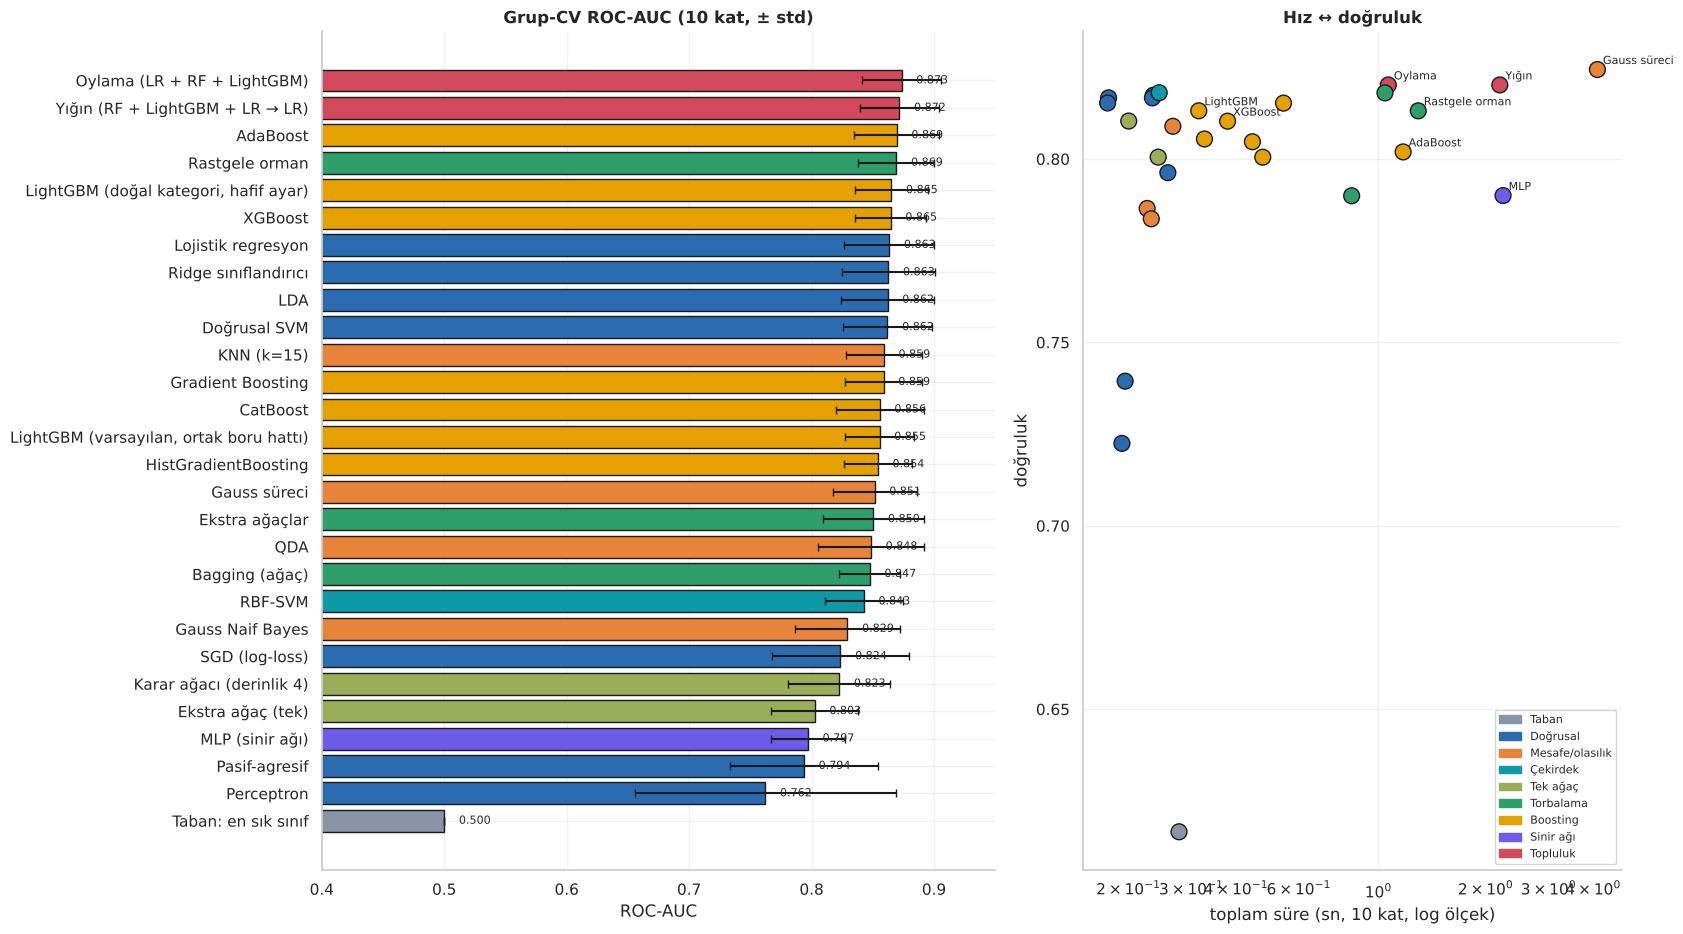

**Basit kural taban çizgisi** («kadınsa kurtulur»): doğruluk **0.789**, AUC **0.770**. Gerçekçi bir model bunun **belirgin üstüne** çıkmalı; çıkmıyorsa karmaşıklık boşunadır.

In [15]:
aile_renk = {"Taban": RENK["gri"], "Doğrusal": RENK["mavi"], "Mesafe/olasılık": RENK["turuncu"], "Çekirdek": RENK["cyan"], "Tek ağaç": "#9AAE5A",
             "Torbalama": RENK["yesil"], "Boosting": RENK["altin"], "Sinir ağı": RENK["mor"], "Topluluk": RENK["pembe"]}
yr = yaris.sort_values("ROC-AUC")
fig, ax = plt.subplots(1, 2, figsize=(17, 9.5), gridspec_kw={"width_ratios": [1.25, 1]})
ax[0].barh(yr.index, yr["ROC-AUC"], xerr=yr["AUC std"], color=[aile_renk[a] for a in yr["Aile"]], edgecolor="k", capsize=3)
ax[0].set(xlim=(0.4, 0.95), title="Grup-CV ROC-AUC (10 kat, ± std)", xlabel="ROC-AUC")
for a, r_ in zip(ax[0].patches, yr["ROC-AUC"]): ax[0].text(r_ + 0.012, a.get_y() + a.get_height() / 2, f"{r_:.3f}", va="center", fontsize=8)
ax[1].scatter(yaris["Süre (sn)"], yaris["Doğruluk"], s=130, c=[aile_renk[a] for a in yaris["Aile"]], edgecolor="k")
for ad, r_ in yaris.iterrows():
    if r_["Sıra (AUC)"] <= 6 or r_["Süre (sn)"] > yaris["Süre (sn)"].quantile(0.9): ax[1].annotate(ad.split(" (")[0], (r_["Süre (sn)"], r_["Doğruluk"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax[1].set(xscale="log", xlabel="toplam süre (sn, 10 kat, log ölçek)", ylabel="doğruluk", title="Hız ↔ doğruluk")
from matplotlib.patches import Patch
ax[1].legend(handles=[Patch(color=c, label=a) for a, c in aile_renk.items()], fontsize=8, loc="lower right")
plt.tight_layout(); kaydet(fig, "05_buyuk_yaris"); plt.show()
kural = pd.Series({"Doğruluk": ((Xtr["Sex"] == "female").astype(int) == ytr).mean(), "ROC-AUC": roc_auc_score(ytr, (Xtr["Sex"] == "female").astype(int))})
display(Markdown(f"**Basit kural taban çizgisi** («kadınsa kurtulur»): doğruluk **{kural['Doğruluk']:.3f}**, AUC **{kural['ROC-AUC']:.3f}**. Gerçekçi bir model bunun **belirgin üstüne** çıkmalı; çıkmıyorsa karmaşıklık boşunadır."))

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

**Topluluklar** (oylama, yığın) tepede; tek başına rastgele orman, AdaBoost, ayarlanmamış LightGBM/XGBoost/CatBoost ve hatta **lojistik regresyon** birbirine çok yakın. Geride kalanlar: perceptron, pasif-agresif, tek ağaçlar, Naif Bayes, MLP. Yani bu küçük ve çoğunlukla kategorik veride **karmaşık bir algoritma net bir üstünlük sağlamıyor**; ayrıca varsayılan LightGBM/XGBoost eğitim doğruluğunda ezber işareti veriyor (tabloda *Eğitim doğruluğu* sütunu). Farklar fold standart sapmalarıyla iç içe; bir sonraki bölümde **şans mı gerçek mi** diye bakıyoruz.

</td></tr></table>

<a id="p8"></a>

<p align="center">
  <img src="assets/proje_08.svg" width="100%" alt="Bölüm 8 · Yarışın röntgeni">
</p>

Test setini **hâlâ açmıyoruz**. Yarışın güvenilirliğini üç yoldan sınıyoruz:

1. **Taze katlar:** farklı rastgele tohumlarla yeni gruplu katlarda sıralama aynı mı?
2. **Bootstrap:** üst sıradaki iki model arasındaki fark şanstan ayırt edilebilir mi?
3. **Düzen:** rastgele katlarda sıralama grup katlarındakiyle aynı mı?

### 🔁 8.1 · Taze Katlar

,AUC (ilk katlar),AUC (taze katlar),Sıra (ilk),Sıra (taze)
Algoritma,,,,
Oylama (LR + RF + LightGBM),0.8735,0.8765,1,1
Yığın (RF + LightGBM + LR → LR),0.8717,0.8750,2,2
AdaBoost,0.8695,0.8666,3,7
Rastgele orman,0.8692,0.8734,4,3
"LightGBM (doğal kategori, hafif ayar)",0.8651,0.8693,5,4
XGBoost,0.8645,0.8659,6,11
Lojistik regresyon,0.8634,0.8673,7,6
Ridge sınıflandırıcı,0.8626,0.8665,8,8
LDA,0.8620,0.8662,9,10


📄 Rapor → outputs/reports/08_taze_katlar.csv
💾 Kaydedildi → outputs/figures/06_taze_katlar.png


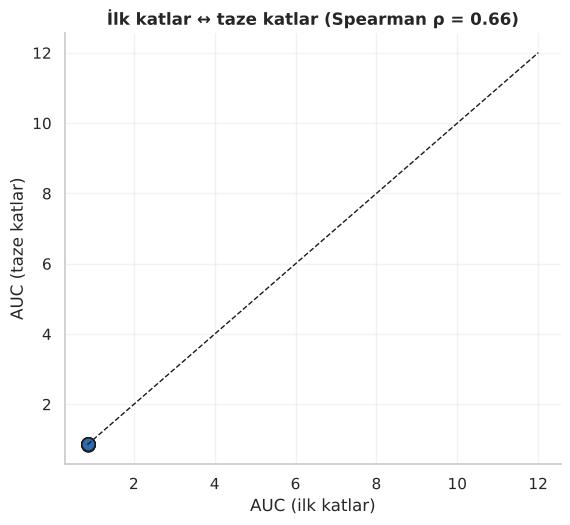

In [16]:
ust = list(yaris.index[:12])
taze = yaris_kos(ust, CV_TAZE)
karsi = pd.DataFrame({"AUC (ilk katlar)": yaris.loc[ust, "ROC-AUC"], "AUC (taze katlar)": taze["ROC-AUC"]})
karsi["Sıra (ilk)"] = karsi["AUC (ilk katlar)"].rank(ascending=False).astype(int); karsi["Sıra (taze)"] = karsi["AUC (taze katlar)"].rank(ascending=False).astype(int)
display(karsi.round(4)); rapor_kaydet(karsi, "08_taze_katlar")
from scipy.stats import spearmanr
rho = spearmanr(karsi["AUC (ilk katlar)"], karsi["AUC (taze katlar)"])[0]
fig, ax = plt.subplots(figsize=(6.4, 5.6))
ax.scatter(karsi["AUC (ilk katlar)"], karsi["AUC (taze katlar)"], s=90, color=RENK["mavi"], edgecolor="k")
lo, hi = karsi.min().min() - 0.005, karsi.max().max() + 0.005; ax.plot([lo, hi], [lo, hi], "k--", lw=1)
ax.set(title=f"İlk katlar ↔ taze katlar (Spearman ρ = {rho:.2f})", xlabel="AUC (ilk katlar)", ylabel="AUC (taze katlar)")
kaydet(fig, "06_taze_katlar"); plt.show()

### 🎲 8.2 · Fark Gerçek mi, Şans mı? (Bootstrap)

Üst 6 olasılık üretebilen algoritmanın **katlar dışı (OOF) tahminleri** alınır; yolcular yeniden örneklenerek (2000 kez) lider ile fark dağılımı çıkarılır. %95 aralık **sıfırı kesiyorsa** fark şanstan ayırt edilemez.

,AUC farkı,AUC %95 alt,AUC %95 üst,Doğruluk farkı,Doğr. alt,Doğr. üst,AUC farkı ayırt edilebilir mi?
Rakip,,,,,,,
Yığın (RF + LightGBM + LR → LR),0.0047,0.0017,0.0081,0.0056,-0.0000,0.0126,evet
AdaBoost,0.0091,-0.0031,0.0222,0.0197,-0.0014,0.0407,hayır
Rastgele orman,0.0025,-0.0049,0.0096,0.0056,-0.0070,0.0197,hayır
"LightGBM (doğal kategori, hafif ayar)",0.0022,-0.0088,0.0135,0.0014,-0.0140,0.0169,hayır
XGBoost,0.0015,-0.0086,0.0128,0.0028,-0.0154,0.0211,hayır


📄 Rapor → outputs/reports/09_bootstrap_farklar.csv
Lider (OOF AUC'ye göre): Oylama (LR + RF + LightGBM)
💾 Kaydedildi → outputs/figures/07_bootstrap_farklar.png


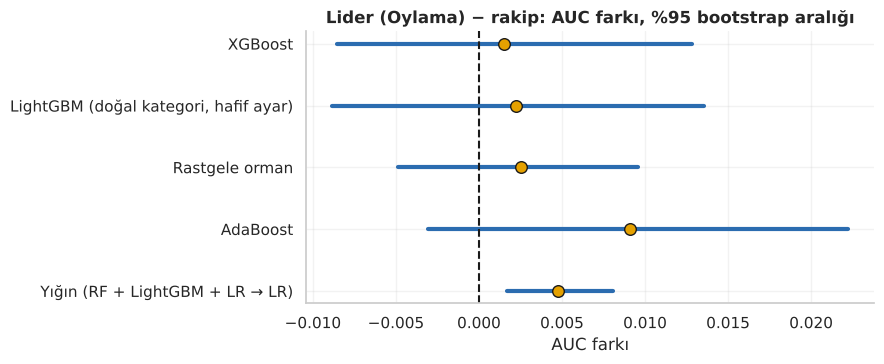

In [17]:
adaylar = [a for a in yaris.index if not np.isnan(yaris.loc[a, "Log-loss"]) and a != "Taban: en sık sınıf"][:6]
oof_bol = list(StratifiedGroupKFold(5, shuffle=True, random_state=7).split(Xtr, ytr, gruplar))
OOF = {a: cross_val_predict(clone(yarisci[a][1]), Xtr, ytr, cv=oof_bol, method="predict_proba", n_jobs=4)[:, 1] for a in adaylar}
rng = np.random.default_rng(R); idx = rng.integers(0, len(ytr), size=(2000, len(ytr)))
lider = adaylar[0]
def boot_fark(a, metrik):
    f = []
    for i in idx:
        yi = ytr[i]
        if len(np.unique(yi)) < 2: continue
        if metrik == "auc": f.append(roc_auc_score(yi, OOF[lider][i]) - roc_auc_score(yi, OOF[a][i]))
        else: f.append(accuracy_score(yi, OOF[lider][i] > .5) - accuracy_score(yi, OOF[a][i] > .5))
    return np.percentile(f, [2.5, 50, 97.5])
satir = []
for a in adaylar[1:]:
    ka = boot_fark(a, "acc"); au = boot_fark(a, "auc")
    satir.append({"Rakip": a, "AUC farkı": au[1], "AUC %95 alt": au[0], "AUC %95 üst": au[2], "Doğruluk farkı": ka[1], "Doğr. alt": ka[0], "Doğr. üst": ka[2],
                  "AUC farkı ayırt edilebilir mi?": "evet" if au[0] > 0 or au[2] < 0 else "hayır"})
bs = pd.DataFrame(satir).set_index("Rakip"); display(bs.round(4)); rapor_kaydet(bs, "09_bootstrap_farklar")
print(f"Lider (OOF AUC'ye göre): {lider}")
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, (a, r_) in enumerate(bs.iterrows()):
    ax.plot([r_["AUC %95 alt"], r_["AUC %95 üst"]], [i, i], "-", color=RENK["mavi"], lw=3); ax.scatter(r_["AUC farkı"], i, color=RENK["altin"], edgecolor="k", s=70, zorder=3)
ax.axvline(0, color="k", ls="--"); ax.set_yticks(range(len(bs))); ax.set_yticklabels(bs.index); ax.set(title=f"Lider ({lider.split(' (')[0]}) − rakip: AUC farkı, %95 bootstrap aralığı", xlabel="AUC farkı")
plt.tight_layout(); kaydet(fig, "07_bootstrap_farklar"); plt.show()

### 🧭 8.3 · Rastgele Katlarda Sıralama Değişiyor mu?

In [18]:
rast = yaris_kos(ust, CV_RASTGELE)
duz = pd.DataFrame({"AUC (grup katları)": yaris.loc[ust, "ROC-AUC"], "AUC (rastgele katlar)": rast["ROC-AUC"]})
duz["Sıra (grup)"] = duz.iloc[:, 0].rank(ascending=False).astype(int); duz["Sıra (rastgele)"] = duz.iloc[:, 1].rank(ascending=False).astype(int)
display(duz.round(4)); rapor_kaydet(duz, "10_rastgele_vs_grup_siralama")
rho2 = spearmanr(duz.iloc[:, 0], duz.iloc[:, 1])[0]
ort_fark = (duz.iloc[:, 1] - duz.iloc[:, 0]).mean()
display(Markdown(f"**Okuma:** rastgele katlar AUC'yi ortalama **{ort_fark:+.3f}** şişiriyor; iki düzen arasındaki sıralama uyumu Spearman ρ = **{rho2:.2f}**. Şişme **tüm modellerde** var, yani rastgele katlardaki skorlar yeni gruplar için **iyimser**dir."))

,AUC (grup katları),AUC (rastgele katlar),Sıra (grup),Sıra (rastgele)
Algoritma,,,,
Oylama (LR + RF + LightGBM),0.8735,0.8869,1,1
Yığın (RF + LightGBM + LR → LR),0.8717,0.8864,2,2
AdaBoost,0.8695,0.8727,3,7
Rastgele orman,0.8692,0.8841,4,4
"LightGBM (doğal kategori, hafif ayar)",0.8651,0.8828,5,5
XGBoost,0.8645,0.8851,6,3
Lojistik regresyon,0.8634,0.8669,7,8
Ridge sınıflandırıcı,0.8626,0.8652,8,10
LDA,0.8620,0.8648,9,12


📄 Rapor → outputs/reports/10_rastgele_vs_grup_siralama.csv


**Okuma:** rastgele katlar AUC'yi ortalama **+0.010** şişiriyor; iki düzen arasındaki sıralama uyumu Spearman ρ = **0.72**. Şişme **tüm modellerde** var, yani rastgele katlardaki skorlar yeni gruplar için **iyimser**dir.

<a id="p9"></a>

<p align="center">
  <img src="assets/proje_09.svg" width="100%" alt="Bölüm 9 · LightGBM yakından">
</p>

Şimdi **LightGBM'in düğmelerini tek tek** çeviriyoruz. Her deney grup katlarında; eğitim ve doğrulama log-loss'u **yan yana**, çünkü açılan makas **ezberin** işaretidir.

### 📉 9.1 · Öğrenme Eğrisi ve Erken Durdurma

💾 Kaydedildi → outputs/figures/08_ogrenme_egrisi.png


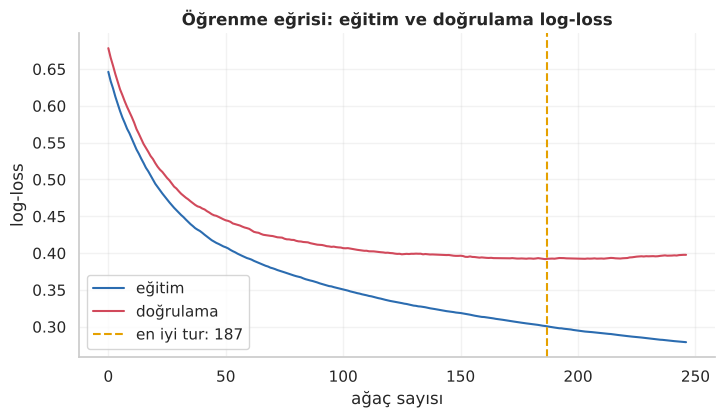

Erken durdurma: en iyi tur = 187 | o turdaki doğrulama log-loss = 0.3919


In [19]:
fi, vi = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=3).split(Xtr, ytr, gruplar))
on = lgb_d(**{**LGB_TEMEL, "n_estimators": 1000, "learning_rate": 0.03})[:-1].fit(Xtr.iloc[fi], ytr[fi])
A, V = on.transform(Xtr.iloc[fi]), on.transform(Xtr.iloc[vi])
kayit = {}
es = LGBMClassifier(**{**LGB_TEMEL, "n_estimators": 1000, "learning_rate": 0.03}).fit(A, ytr[fi], eval_set=[(A, ytr[fi]), (V, ytr[vi])], eval_names=["egitim", "dogrulama"], eval_metric="binary_logloss",
        callbacks=[lgb.early_stopping(60, verbose=False), lgb.record_evaluation(kayit)])
egri = pd.DataFrame({"eğitim": kayit["egitim"]["binary_logloss"], "doğrulama": kayit["dogrulama"]["binary_logloss"]})
fig, ax = plt.subplots(figsize=(8.2, 4.2))
ax.plot(egri["eğitim"], color=RENK["mavi"], label="eğitim"); ax.plot(egri["doğrulama"], color=RENK["pembe"], label="doğrulama")
ax.axvline(es.best_iteration_, color=RENK["altin"], ls="--", label=f"en iyi tur: {es.best_iteration_}"); ax.legend()
ax.set(title="Öğrenme eğrisi: eğitim ve doğrulama log-loss", xlabel="ağaç sayısı", ylabel="log-loss")
kaydet(fig, "08_ogrenme_egrisi"); plt.show()
print("Erken durdurma: en iyi tur =", es.best_iteration_, "| o turdaki doğrulama log-loss =", round(egri["doğrulama"].min(), 4))

### 🐢 9.2 · Öğrenme Hızı × Ağaç Sayısı

Küçük η daha çok ağaç ister; ikisi birlikte okunmalı.

💾 Kaydedildi → outputs/figures/09_hiz_x_agac.png


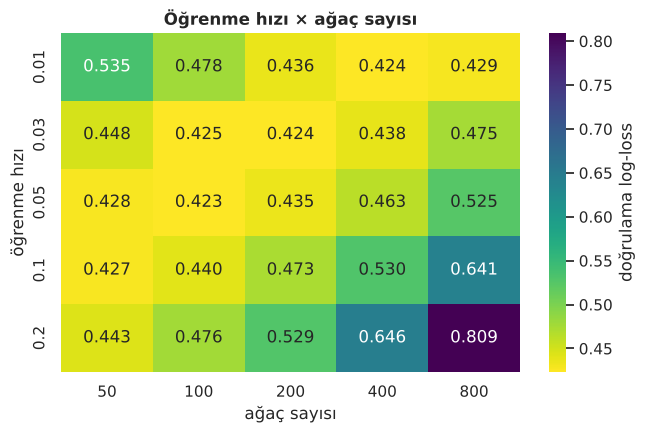

📄 Rapor → outputs/reports/11_hiz_x_agac.csv
En iyi hücre: (np.float64(0.05), np.int64(100)) → 0.4234


In [20]:
hiz_ag = {(lr, n): cv_lgb(learning_rate=lr, n_estimators=n)["val_logloss"] for lr in [0.01, 0.03, 0.05, 0.1, 0.2] for n in [50, 100, 200, 400, 800]}
isi = pd.Series(hiz_ag).unstack(); isi.index.name = "öğrenme hızı"; isi.columns.name = "ağaç sayısı"
fig, ax = plt.subplots(figsize=(7.4, 4.4)); sns.heatmap(isi, annot=True, fmt=".3f", cmap="viridis_r", ax=ax, cbar_kws={"label": "doğrulama log-loss"})
ax.set(title="Öğrenme hızı × ağaç sayısı"); kaydet(fig, "09_hiz_x_agac"); plt.show(); rapor_kaydet(isi, "11_hiz_x_agac")
print("En iyi hücre:", isi.stack().idxmin(), "→", round(isi.stack().min(), 4))

### 🍃 9.3 · LightGBM'in Özel Düğmesi: `num_leaves` × `max_depth`

💾 Kaydedildi → outputs/figures/10_yaprak_x_derinlik.png


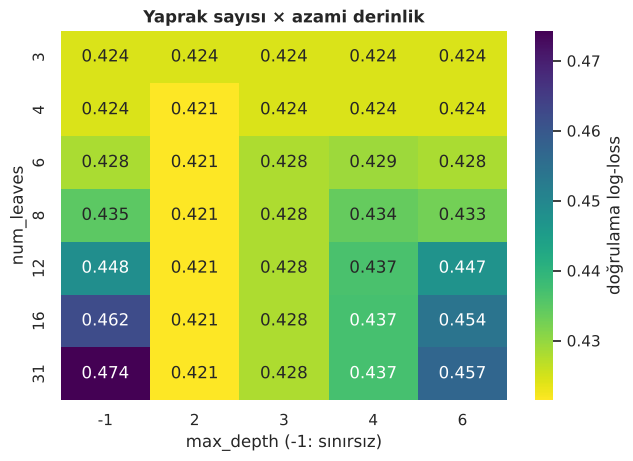

📄 Rapor → outputs/reports/12_yaprak_x_derinlik.csv


In [21]:
yd = {(nl, md): cv_lgb(num_leaves=nl, max_depth=md)["val_logloss"] for nl in [3, 4, 6, 8, 12, 16, 31] for md in [2, 3, 4, 6, -1]}
isi2 = pd.Series(yd).unstack(); isi2.index.name = "num_leaves"; isi2.columns.name = "max_depth (-1: sınırsız)"
fig, ax = plt.subplots(figsize=(7.2, 4.8)); sns.heatmap(isi2, annot=True, fmt=".3f", cmap="viridis_r", ax=ax, cbar_kws={"label": "doğrulama log-loss"})
ax.set(title="Yaprak sayısı × azami derinlik"); kaydet(fig, "10_yaprak_x_derinlik"); plt.show(); rapor_kaydet(isi2, "12_yaprak_x_derinlik")

### 🧱 9.4 · Küçük Verinin Anahtarı: `min_child_samples`

💾 Kaydedildi → outputs/figures/11_min_child_samples.png


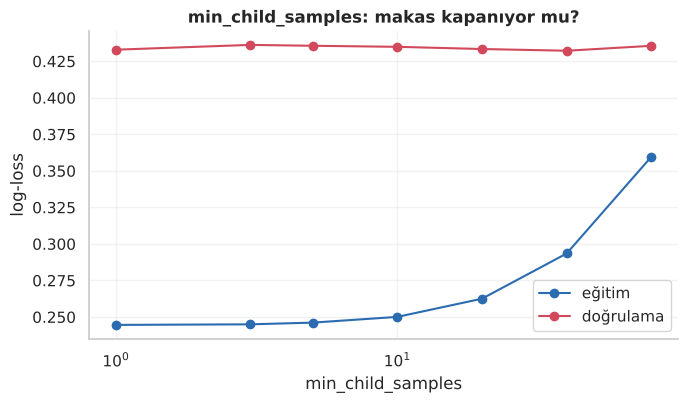

,val_logloss,tr_logloss,AUC,Doğruluk,Doğruluk std
1,0.4329,0.2446,0.8666,0.8160,0.0217
3,0.4362,0.2450,0.8639,0.8082,0.0242
5,0.4356,0.2462,0.8654,0.8131,0.0244
10,0.4349,0.2501,0.8651,0.8131,0.0257
20,0.4334,0.2625,0.8669,0.8216,0.0238
40,0.4322,0.2935,0.8672,0.8103,0.0200
80,0.4356,0.3597,0.8619,0.8033,0.0266


📄 Rapor → outputs/reports/13_min_child_samples.csv


In [22]:
def tara(ad, degerler, **sabit):
    return pd.DataFrame({d: cv_lgb(**{**sabit, ad: d}) for d in degerler}).T
mc = tara("min_child_samples", [1, 3, 5, 10, 20, 40, 80])
fig, ax = plt.subplots(figsize=(7.6, 4)); ax.plot(mc.index, mc["tr_logloss"], "o-", color=RENK["mavi"], label="eğitim"); ax.plot(mc.index, mc["val_logloss"], "o-", color=RENK["pembe"], label="doğrulama")
ax.set(title="min_child_samples: makas kapanıyor mu?", xlabel="min_child_samples", ylabel="log-loss", xscale="log"); ax.legend()
kaydet(fig, "11_min_child_samples"); plt.show(); display(mc.round(4)); rapor_kaydet(mc, "13_min_child_samples")

### 🎲 9.5 · Alt Örnekleme: `subsample` × `colsample_bytree`

💾 Kaydedildi → outputs/figures/12_alt_ornekleme.png


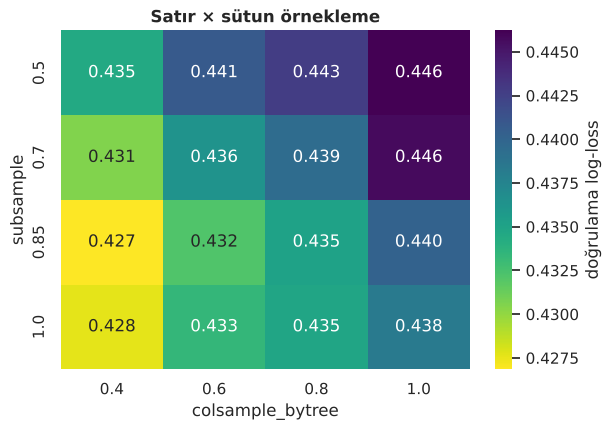

📄 Rapor → outputs/reports/14_alt_ornekleme.csv


In [23]:
ao = {(s, c): cv_lgb(subsample=s, colsample_bytree=c)["val_logloss"] for s in [0.5, 0.7, 0.85, 1.0] for c in [0.4, 0.6, 0.8, 1.0]}
isi3 = pd.Series(ao).unstack(); isi3.index.name = "subsample"; isi3.columns.name = "colsample_bytree"
fig, ax = plt.subplots(figsize=(6.6, 4.4)); sns.heatmap(isi3, annot=True, fmt=".3f", cmap="viridis_r", ax=ax, cbar_kws={"label": "doğrulama log-loss"})
ax.set(title="Satır × sütun örnekleme"); kaydet(fig, "12_alt_ornekleme"); plt.show(); rapor_kaydet(isi3, "14_alt_ornekleme")

### 🛡️ 9.6 · Düzenleme Düğmeleri: λ (`reg_lambda`), α (`reg_alpha`), `min_split_gain`

💾 Kaydedildi → outputs/figures/13_duzenleme.png


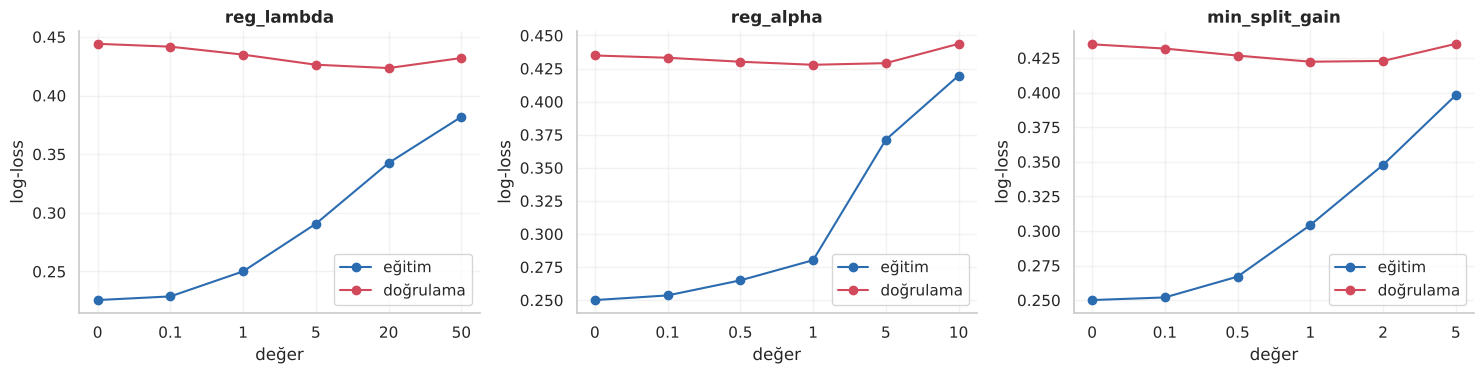

📄 Rapor → outputs/reports/15_duzenleme.csv


In [24]:
fig, eksen = plt.subplots(1, 3, figsize=(15, 3.9)); duzenleme = {}
for ax, (ad, dg) in zip(eksen, {"reg_lambda": [0, 0.1, 1, 5, 20, 50], "reg_alpha": [0, 0.1, 0.5, 1, 5, 10], "min_split_gain": [0, 0.1, 0.5, 1, 2, 5]}.items()):
    t = tara(ad, dg); duzenleme[ad] = t
    ax.plot(range(len(dg)), t["tr_logloss"], "o-", color=RENK["mavi"], label="eğitim"); ax.plot(range(len(dg)), t["val_logloss"], "o-", color=RENK["pembe"], label="doğrulama")
    ax.set_xticks(range(len(dg))); ax.set_xticklabels(dg); ax.set(title=ad, xlabel="değer", ylabel="log-loss"); ax.legend()
plt.tight_layout(); kaydet(fig, "13_duzenleme"); plt.show()
rapor_kaydet(pd.concat(duzenleme, names=["düğme", "değer"]), "15_duzenleme")

### 🧰 9.7 · Diğer Seçenekler: `boosting_type`, `max_bin`, Sınıf Dengesi, Kategori İşleme

`gbdt` (klasik), `dart` (ağaçları rastgele **bırakarak** eğitir), `rf` (LightGBM'in orman modu) ve **GOSS** (büyük gradyanlı örnekleri tutup küçüklerden az örnek alan veri örnekleme stratejisi, Ke vd., 2017).

,val_logloss,tr_logloss,AUC,Doğruluk,Doğruluk std
gbdt (varsayılan),0.4349,0.2501,0.8651,0.8131,0.0257
dart,0.4352,0.3673,0.8680,0.8082,0.0228
rf (orman modu),0.4461,0.4076,0.8662,0.8019,0.0270
GOSS,0.4366,0.2726,0.8642,0.8110,0.0308
max_bin = 16,0.4409,0.2788,0.8598,0.8089,0.0322
max_bin = 63,0.4387,0.2543,0.8642,0.8145,0.0259
max_bin = 255,0.4349,0.2501,0.8651,0.8131,0.0257
class_weight = balanced,0.4470,0.2590,0.8641,0.7984,0.0310
kategori: cat_smooth = 30,0.4339,0.2507,0.8661,0.8159,0.0229
tek-sıcak boru hattı (doğal kategori yok),0.4323,0.2497,0.8680,0.8209,0.0225


📄 Rapor → outputs/reports/16_lgbm_secenekler.csv
💾 Kaydedildi → outputs/figures/14_lgbm_secenekler.png


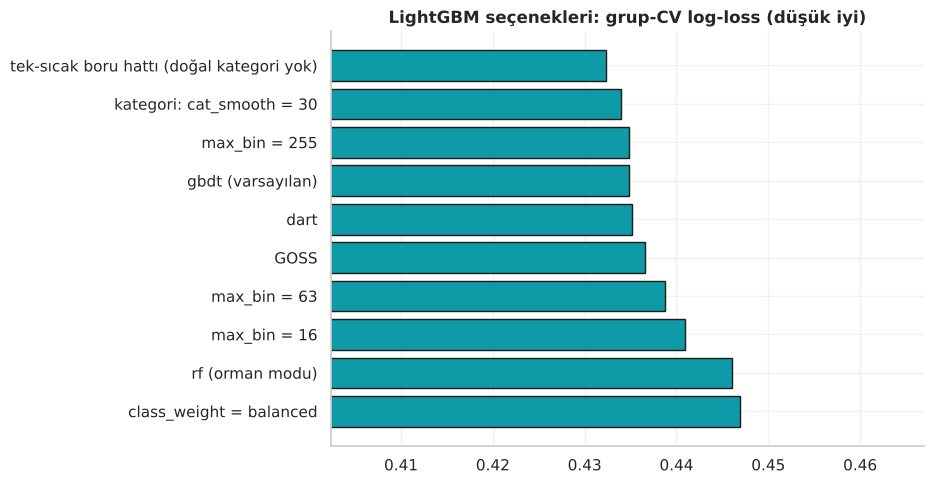

In [25]:
secenekler = {
    "gbdt (varsayılan)": {},
    "dart": {"boosting_type": "dart"},
    "rf (orman modu)": {"boosting_type": "rf", "subsample": 0.8, "subsample_freq": 1},
    "GOSS": {"data_sample_strategy": "goss", "subsample": 1.0, "subsample_freq": 0},
    "max_bin = 16": {"max_bin": 16}, "max_bin = 63": {"max_bin": 63}, "max_bin = 255": {"max_bin": 255},
    "class_weight = balanced": {"class_weight": "balanced"},
    "kategori: cat_smooth = 30": {"cat_smooth": 30, "min_data_per_group": 30},
}
sat = {}
for ad, kw in secenekler.items():
    try: sat[ad] = cv_lgb(**kw)
    except Exception as e: print("atlandı:", ad, "→", str(e)[:80])
secdf = pd.DataFrame(sat).T
# kategori işleme karşılaştırması: doğal kategori ↔ ortak (tek-sıcak) boru hattı
cvr = cross_validate(std(LGBMClassifier(**{**LGB_TEMEL})), Xtr, ytr, cv=CV_GRUP, scoring=SK4, return_train_score=True, n_jobs=4)
secdf.loc["tek-sıcak boru hattı (doğal kategori yok)"] = {"val_logloss": -cvr["test_ll"].mean(), "tr_logloss": -cvr["train_ll"].mean(), "AUC": cvr["test_auc"].mean(), "Doğruluk": cvr["test_acc"].mean(), "Doğruluk std": cvr["test_acc"].std()}
display(secdf.round(4)); rapor_kaydet(secdf, "16_lgbm_secenekler")
fig, ax = plt.subplots(figsize=(9.5, 5)); sd = secdf.sort_values("val_logloss", ascending=False)
ax.barh(sd.index, sd["val_logloss"], color=RENK["cyan"], edgecolor="k"); ax.set_xlim(sd["val_logloss"].min() - 0.03, sd["val_logloss"].max() + 0.02)
ax.set(title="LightGBM seçenekleri: grup-CV log-loss (düşük iyi)"); plt.tight_layout(); kaydet(fig, "14_lgbm_secenekler"); plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Küçük veride en çok **frenler** (küçük `num_leaves`, makul `min_child_samples`, düzenleme, alt örnekleme) fark yaratır; varsayılan bir LightGBM, bu boyutta genellikle **aşırı özgüvenlidir**. `dart` ve `rf` bazen yarışabilir ama yavaş/ayar isteyicidir. GOSS ve kova sayısı bu ölçekte **hız avantajı** getirmez; onlar büyük veri hileleridir.

</td></tr></table>

### 🎞️ 9.8 · Tur Tur Ayrışma (Animasyon)

Doğrulama yolcularında **kurtulanlar** ile **kurtulamayanlar** modelin olasılık çıktısında ağaç eklendikçe **ayrışıyor**. AUC sağ üstte.

🎞️ Animasyon → outputs/figures/15_tur_tur_ayrisma.gif


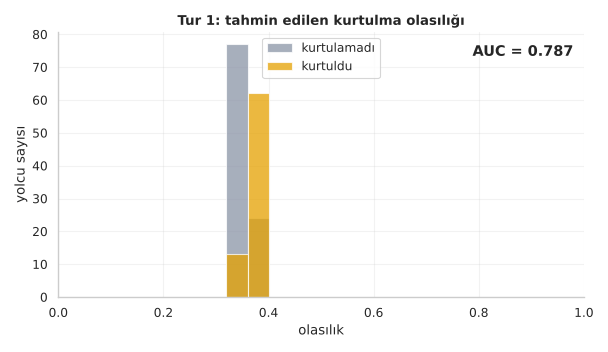

In [26]:
anim_model = LGBMClassifier(**{**LGB_TEMEL, "n_estimators": 150}).fit(A, ytr[fi])
turlar = [1, 2, 3, 5, 8, 12, 20, 35, 60, 100, 150]
pv = {k: anim_model.predict_proba(V, num_iteration=k)[:, 1] for k in turlar}
def kare(i, fig):
    ax = fig.add_subplot(111); k = turlar[i]; p = pv[k]
    ax.hist(p[ytr[vi] == 0], bins=np.linspace(0, 1, 26), alpha=0.75, color=RENK["gri"], label="kurtulamadı")
    ax.hist(p[ytr[vi] == 1], bins=np.linspace(0, 1, 26), alpha=0.75, color=RENK["altin"], label="kurtuldu")
    ax.set(title=f"Tur {k}: tahmin edilen kurtulma olasılığı", xlabel="olasılık", ylabel="yolcu sayısı", xlim=(0, 1)); ax.legend(loc="upper center")
    ax.text(0.98, 0.95, f"AUC = {roc_auc_score(ytr[vi], p):.3f}", transform=ax.transAxes, ha="right", va="top", fontsize=13, fontweight="bold")
gif_kaydet(kare, len(turlar), "15_tur_tur_ayrisma", figsize=(7.6, 4.4), fps=2)

<a id="p10"></a>

<p align="center">
  <img src="assets/proje_10.svg" width="100%" alt="Bölüm 10 · Hiperparametre ayarı">
</p>

### 🎛️ 10.1 · Rastgele Arama (Bergstra ve Bengio, 2012)

Üç boosting kütüphanesi **aynı bütçe mantığıyla** ayarlanır: grup katlarında log-loss'u en küçük yapan ayar aranır. Test seti hâlâ kapalı.

In [27]:
from scipy.stats import loguniform, randint, uniform
cv_ayar = list(StratifiedGroupKFold(5, shuffle=True, random_state=31).split(Xtr, ytr, gruplar))

arama_lgb = RandomizedSearchCV(lgb_d(verbosity=-1, random_state=R, n_jobs=1, subsample_freq=1),
    {"model__n_estimators": randint(80, 500), "model__learning_rate": loguniform(0.01, 0.2), "model__num_leaves": randint(3, 32), "model__max_depth": [-1, 3, 4, 5, 6],
     "model__min_child_samples": randint(5, 60), "model__subsample": uniform(0.6, 0.4), "model__colsample_bytree": uniform(0.5, 0.5),
     "model__reg_lambda": loguniform(1e-2, 30), "model__reg_alpha": loguniform(1e-3, 10), "model__min_split_gain": uniform(0, 0.3)},
    n_iter=40, scoring="neg_log_loss", cv=cv_ayar, n_jobs=4, random_state=R, refit=True)
arama_xgb = RandomizedSearchCV(std(XGBClassifier(verbosity=0, random_state=R, n_jobs=1)),
    {"m__n_estimators": randint(80, 500), "m__learning_rate": loguniform(0.01, 0.2), "m__max_depth": randint(2, 7), "m__min_child_weight": randint(1, 12),
     "m__subsample": uniform(0.6, 0.4), "m__colsample_bytree": uniform(0.5, 0.5), "m__reg_lambda": loguniform(1e-2, 30), "m__gamma": uniform(0, 1.0)},
    n_iter=40, scoring="neg_log_loss", cv=cv_ayar, n_jobs=4, random_state=R, refit=True)
arama_cat = RandomizedSearchCV(std(CatBoostClassifier(verbose=0, random_seed=R, thread_count=1, allow_writing_files=False)),
    {"m__iterations": randint(100, 400), "m__learning_rate": loguniform(0.02, 0.2), "m__depth": randint(3, 7), "m__l2_leaf_reg": loguniform(1, 30)},
    n_iter=14, scoring="neg_log_loss", cv=cv_ayar, n_jobs=4, random_state=R, refit=True)
for ad, ar in [("LightGBM", arama_lgb), ("XGBoost", arama_xgb), ("CatBoost", arama_cat)]:
    t0 = time.perf_counter(); ar.fit(Xtr, ytr); print(f"{ad:<9s} arama bitti ({time.perf_counter() - t0:.0f} sn) | en iyi arama-CV log-loss: {-ar.best_score_:.4f}")
print("\nLightGBM en iyi ayar:")
for k, v in arama_lgb.best_params_.items(): print(f"  {k.split('__')[1]:<18s} {v if not isinstance(v, float) else round(v, 4)}")
sonuclar = pd.DataFrame(arama_lgb.cv_results_).sort_values("rank_test_score")[["rank_test_score", "mean_test_score", "std_test_score"] + [c for c in arama_lgb.cv_results_ if c.startswith("param_")]].head(8)
sonuclar["mean_test_score"] = -sonuclar["mean_test_score"]; display(sonuclar.round(4).rename(columns={"mean_test_score": "log-loss"})); rapor_kaydet(sonuclar, "17_lgbm_arama_ilk8", index=False)

LightGBM  arama bitti (3 sn) | en iyi arama-CV log-loss: 0.4299


XGBoost   arama bitti (3 sn) | en iyi arama-CV log-loss: 0.4217


CatBoost  arama bitti (2 sn) | en iyi arama-CV log-loss: 0.4220

LightGBM en iyi ayar:
  colsample_bytree   0.6094
  learning_rate      0.0532
  max_depth          5
  min_child_samples  53
  min_split_gain     0.0195
  n_estimators       131
  num_leaves         14
  reg_alpha          0.0102
  reg_lambda         0.5358
  subsample          0.7204


,rank_test_score,log-loss,std_test_score,param_model__colsample_bytree,param_model__learning_rate,param_model__max_depth,param_model__min_child_samples,param_model__min_split_gain,param_model__n_estimators,param_model__num_leaves,param_model__reg_alpha,param_model__reg_lambda,param_model__subsample
16,1,0.4299,0.0704,0.6094,0.0532,5,53,0.0195,131,14,0.0102,0.5358,0.7204
4,2,0.4301,0.0690,0.7816,0.0317,3,57,0.0693,171,17,0.5408,1.3214,0.9333
18,3,0.4324,0.0738,0.5724,0.0433,5,59,0.2285,202,19,0.8182,0.1900,0.8529
30,4,0.4324,0.0896,0.5486,0.0631,3,31,0.0886,352,10,0.6139,2.7709,0.7438
1,5,0.4332,0.0956,0.8006,0.0834,6,6,0.2166,493,8,0.0010,28.1864,0.8470
37,6,0.4333,0.0680,0.6199,0.0132,-1,44,0.2804,464,18,0.1166,1.9269,0.7743
20,7,0.4339,0.0812,0.5083,0.0464,4,24,0.1936,387,11,0.5804,0.2212,0.9747
23,8,0.4344,0.0840,0.9233,0.1300,-1,28,0.2553,192,10,1.3847,2.1191,0.8323


📄 Rapor → outputs/reports/17_lgbm_arama_ilk8.csv


### 🔍 10.2 · Taze Katlarda Doğrulama ve Final Seçimi

Aramada seçilen ayarın skoru **iyimserdir** (en iyiyi seçtik). Bu yüzden varsayılan ve ayarlı sürümler **hiç kullanılmamış taze gruplu katlarda** karşılaştırılır.

**Seçim kuralı (sonuçlar görülmeden yazıldı):** taze katlarda log-loss'u en düşük **ayarlı** boosting modeli en iyi sayılır; **LightGBM, bu en iyiden en çok 0,005 log-loss gerideyse** (fark pratikte ayırt edilemez) final olarak LightGBM seçilir.

,Doğruluk,Doğruluk std,F1,ROC-AUC,Log-loss,Eğitim doğruluğu,Süre (sn)
Algoritma,,,,,,,
XGBoost ayarlı,0.8028,0.0332,0.7231,0.8629,0.4296,0.8645,0.5307
CatBoost ayarlı,0.8131,0.0399,0.7388,0.8631,0.4317,0.8690,0.5501
LightGBM ayarlı,0.8014,0.0407,0.7225,0.8643,0.4331,0.8567,0.3667
CatBoost varsayılan,0.8103,0.0439,0.7323,0.8484,0.4486,0.9126,1.9598
LightGBM varsayılan,0.7939,0.0372,0.7255,0.8476,0.5223,0.9642,0.4132
XGBoost varsayılan,0.7766,0.0308,0.7035,0.8379,0.6113,0.9780,0.4193


📄 Rapor → outputs/reports/18_taze_katlar_ayarli.csv


**Seçim kuralı sonucu:** LightGBM ayarlı, en iyiden (XGBoost ayarlı) 0.0035 log-loss geride (≤ 0,005) → **final: LightGBM ayarlı**

LightGBM  log-loss: varsayılan 0.5223 → ayarlı 0.4331 (-0.0892) | AUC: 0.8476 → 0.8643
XGBoost   log-loss: varsayılan 0.6113 → ayarlı 0.4296 (-0.1817) | AUC: 0.8379 → 0.8629
CatBoost  log-loss: varsayılan 0.4486 → ayarlı 0.4317 (-0.0169) | AUC: 0.8484 → 0.8631
💾 Kaydedildi → outputs/figures/16_ayar_taze_katlar.png


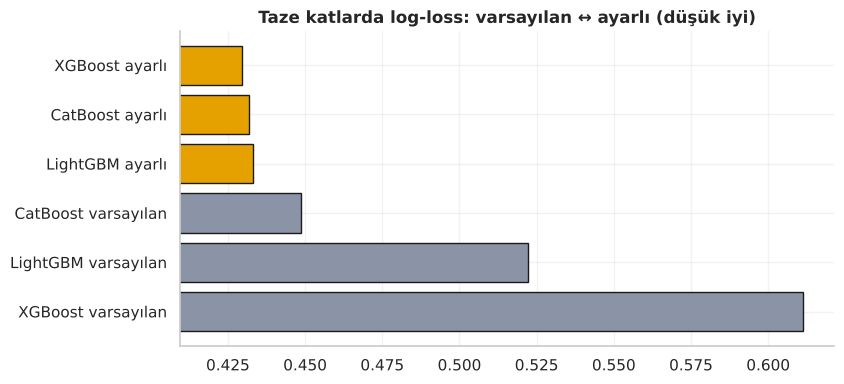

In [28]:
TAZE_MODELLER = {
    "LightGBM varsayılan": ("Boosting", lgb_d(verbosity=-1, random_state=R, n_jobs=1)),
    "LightGBM ayarlı": ("Boosting", clone(arama_lgb.best_estimator_)),
    "XGBoost varsayılan": ("Boosting", std(XGBClassifier(verbosity=0, random_state=R, n_jobs=1))),
    "XGBoost ayarlı": ("Boosting", clone(arama_xgb.best_estimator_)),
    "CatBoost varsayılan": ("Boosting", std(CatBoostClassifier(verbose=0, random_seed=R, thread_count=1, allow_writing_files=False))),
    "CatBoost ayarlı": ("Boosting", clone(arama_cat.best_estimator_)),
}
CV_TAZE2 = list(chain.from_iterable(StratifiedGroupKFold(5, shuffle=True, random_state=s).split(Xtr, ytr, gruplar) for s in (41, 42, 43)))
taze2 = yaris_kos(list(TAZE_MODELLER), CV_TAZE2, TAZE_MODELLER).sort_values("Log-loss")
display(taze2.drop(columns=["Aile", "AUC std"]).round(4)); rapor_kaydet(taze2, "18_taze_katlar_ayarli")
ayarli = taze2[taze2.index.str.contains("ayarlı")]
en_iyi_ayarli = ayarli["Log-loss"].idxmin(); fark = ayarli.loc["LightGBM ayarlı", "Log-loss"] - ayarli.loc[en_iyi_ayarli, "Log-loss"]
if fark <= 0.005: kural_sonucu = f"LightGBM ayarlı, en iyiden ({en_iyi_ayarli}) {fark:.4f} log-loss geride (≤ 0,005) → **final: LightGBM ayarlı**"
else: kural_sonucu = f"LightGBM ayarlı, en iyiden ({en_iyi_ayarli}) {fark:.4f} geride (> 0,005). Kural gereği en iyi **{en_iyi_ayarli}**; ancak bu derste LightGBM'i incelemeyi sürdürüyoruz ve bu durumu açıkça not ediyoruz."
display(Markdown("**Seçim kuralı sonucu:** " + kural_sonucu))
for ad in ["LightGBM", "XGBoost", "CatBoost"]:
    d = taze2.loc[f"{ad} varsayılan", "Log-loss"]; a = taze2.loc[f"{ad} ayarlı", "Log-loss"]
    print(f"{ad:<9s} log-loss: varsayılan {d:.4f} → ayarlı {a:.4f} ({a - d:+.4f}) | AUC: {taze2.loc[f'{ad} varsayılan','ROC-AUC']:.4f} → {taze2.loc[f'{ad} ayarlı','ROC-AUC']:.4f}")
LGB_AYARLI = arama_lgb.best_estimator_      # eğitim setinin tamamıyla yeniden eğitilmiş boru hattı
fig, ax = plt.subplots(figsize=(8.6, 4)); t = taze2.sort_values("Log-loss", ascending=False)
ax.barh(t.index, t["Log-loss"], color=[RENK["altin"] if "ayarlı" in a else RENK["gri"] for a in t.index], edgecolor="k"); ax.set_xlim(t["Log-loss"].min() - 0.02, t["Log-loss"].max() + 0.01)
ax.set(title="Taze katlarda log-loss: varsayılan ↔ ayarlı (düşük iyi)"); plt.tight_layout(); kaydet(fig, "16_ayar_taze_katlar"); plt.show()

<a id="p11"></a>

<p align="center">
  <img src="assets/proje_11.svg" width="100%" alt="Bölüm 11 · Özellik önemi">
</p>

Model neye bakarak karar veriyor? Dört bakış açısı, çünkü **tek bir önem ölçüsü yanıltabilir**:

| Yöntem | Ne ölçer? | Zayıflığı |
|:--|:--|:--|
| **Split** | Özelliğin kaç kez bölünmede kullanıldığı | Çok değerli sütunları kayırır |
| **Gain** | Bölünmelerin toplam kazancı | Eğitim verisine dayanır |
| **Permütasyon** | Sütunu karıştırınca doğrulama AUC'sinin düşüşü | İlişkili sütunlarda paylaşır |
| **TreeSHAP** | Her tahmin için özellik katkısı (Lundberg vd., 2020) | Yorumu dikkat ister |

,Split,Gain,Split %,Gain %,Permütasyon (AUC düşüşü),Ort. |SHAP|
Özellik,,,,,,
Sex,45,859.274,6.089,25.347,0.049,0.692
Unvan,43,778.771,5.819,22.973,0.048,0.671
Pclass,86,544.897,11.637,16.074,0.082,0.584
Age,262,481.045,35.453,14.190,0.013,0.307
Fare,221,524.586,29.905,15.475,-0.002,0.290
Embarked,35,99.738,4.736,2.942,0.005,0.188
SibSp,29,72.929,3.924,2.151,0.003,0.124
Parch,18,28.752,2.436,0.848,-0.003,0.072


📄 Rapor → outputs/reports/19_ozellik_onemi.csv
Doğrulama: SHAP katkılarının toplamı = ham skor mu? En büyük fark: 3.9968028886505635e-15


💾 Kaydedildi → outputs/figures/17_onem_dort_bakis.png


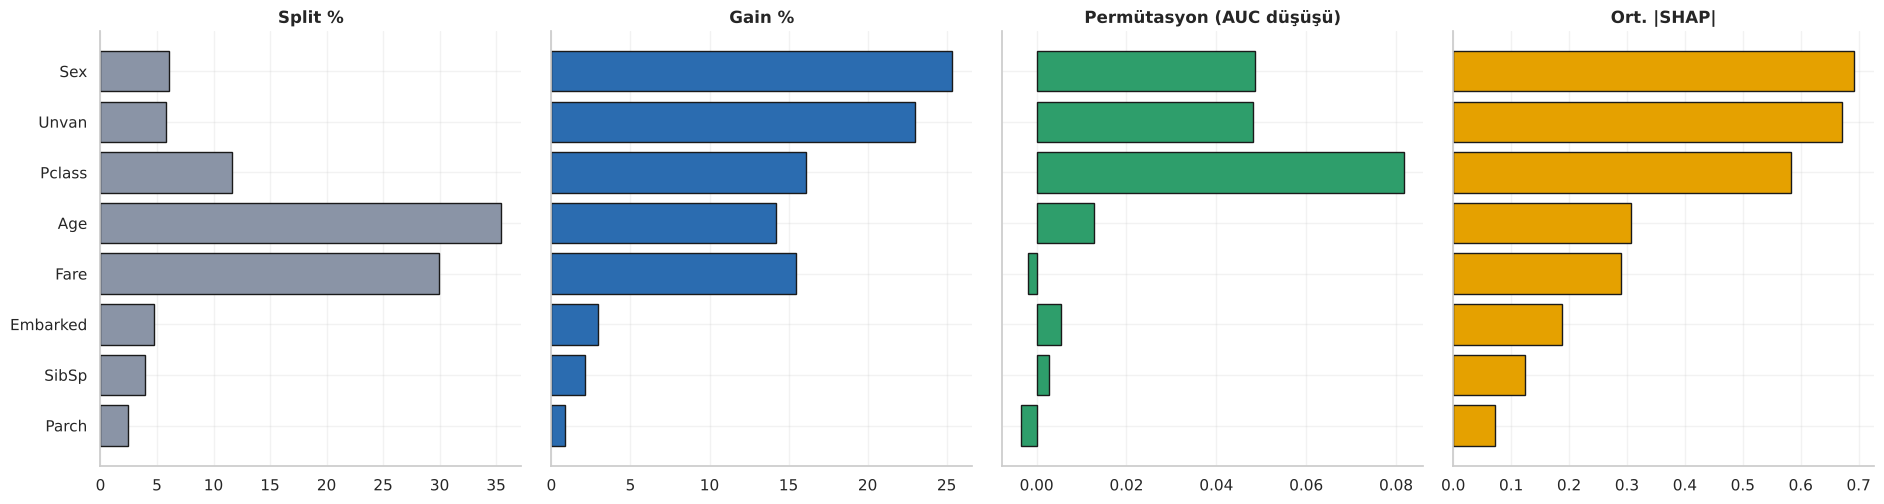

In [29]:
on_f = LGB_AYARLI[:-1]; XT = on_f.transform(Xtr); mdl = LGB_AYARLI.named_steps["model"]; booster = mdl.booster_
imp = pd.DataFrame({"Özellik": booster.feature_name(), "Split": booster.feature_importance("split"), "Gain": booster.feature_importance("gain")})
imp["Split %"] = 100 * imp["Split"] / imp["Split"].sum(); imp["Gain %"] = 100 * imp["Gain"] / imp["Gain"].sum()

# Permütasyon: modeli grup bazlı ayrılmış bir eğitim bölümünde eğit, ayrılan bölümde karıştır
fi2, vi2 = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=5).split(Xtr, ytr, gruplar))
pm = clone(LGB_AYARLI).fit(Xtr.iloc[fi2], ytr[fi2]); Vt = pm[:-1].transform(Xtr.iloc[vi2])
pi = permutation_importance(pm.named_steps["model"], Vt, ytr[vi2], scoring="roc_auc", n_repeats=30, random_state=R)
imp["Permütasyon (AUC düşüşü)"] = pd.Series(pi.importances_mean, index=Vt.columns).reindex(imp["Özellik"]).to_numpy()

# TreeSHAP: LightGBM'in yerleşik pred_contrib çıktısı (son sütun taban değer)
sv = booster.predict(XT, pred_contrib=True); shap_ort = np.abs(sv[:, :-1]).mean(0)
imp["Ort. |SHAP|"] = pd.Series(shap_ort, index=booster.feature_name()).reindex(imp["Özellik"]).to_numpy()
imp = imp.set_index("Özellik").sort_values("Ort. |SHAP|", ascending=False); display(imp.round(3)); rapor_kaydet(imp, "19_ozellik_onemi")
print("Doğrulama: SHAP katkılarının toplamı = ham skor mu? En büyük fark:", float(np.abs(sv.sum(1) - booster.predict(XT, raw_score=True)).max()))

fig, ax = plt.subplots(1, 4, figsize=(19, 5.2), sharey=True); sira = imp.index[::-1]
for a, (kol, renk) in zip(ax, [("Split %", RENK["gri"]), ("Gain %", RENK["mavi"]), ("Permütasyon (AUC düşüşü)", RENK["yesil"]), ("Ort. |SHAP|", RENK["altin"])]):
    a.barh(sira, imp.loc[sira, kol], color=renk, edgecolor="k"); a.set_title(kol)
plt.tight_layout(); kaydet(fig, "17_onem_dort_bakis"); plt.show()

### 🐝 11.2 · SHAP Özeti: Hangi Değer, Hangi Yöne İtiyor?

Her nokta bir yolcu. Sağdaki noktalar **kurtulma olasılığını artırır**, soldakiler **azaltır** (log-odds ölçeğinde). Renk, özelliğin değeridir (kırmızı yüksek, mavi düşük; kategoriler için kod sırası; gri eksik).

💾 Kaydedildi → outputs/figures/18_shap_ozeti.png


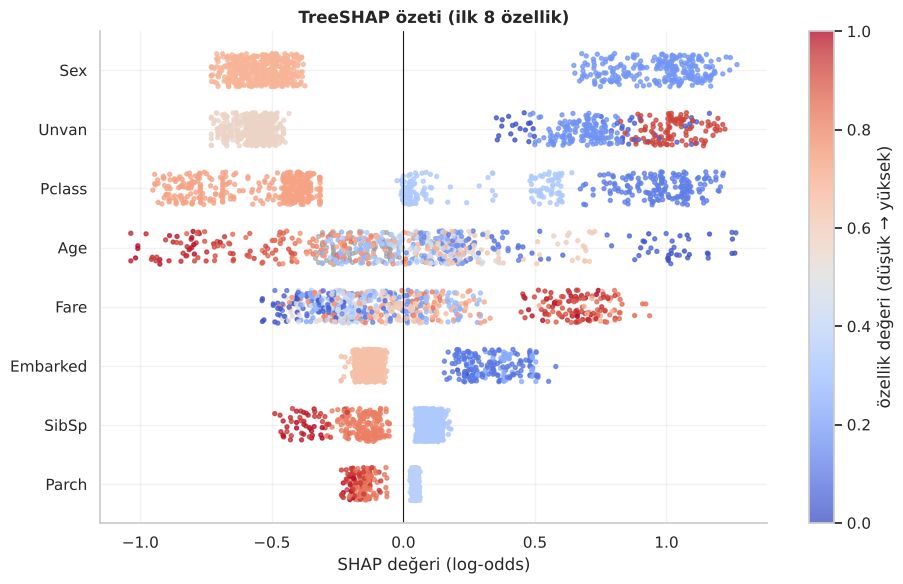

In [30]:
ilk = list(imp.index[:8]); rng_j = np.random.default_rng(R)
fig, ax = plt.subplots(figsize=(9.6, 6))
for k, f in enumerate(ilk[::-1]):
    j = booster.feature_name().index(f); x = sv[:, j]; col = XT[f]
    if str(col.dtype) == "category": v = col.cat.codes.replace(-1, np.nan).astype(float)
    else: v = col.astype(float)
    r_ = v.rank(pct=True).to_numpy() if v.notna().any() else np.full(len(v), np.nan)
    nan = np.isnan(r_); y = k + rng_j.uniform(-0.28, 0.28, len(x))
    ax.scatter(x[nan], y[nan], s=8, color="#9AA0A6", alpha=0.6); sc = ax.scatter(x[~nan], y[~nan], s=8, c=r_[~nan], cmap="coolwarm", alpha=0.75, vmin=0, vmax=1)
ax.set_yticks(range(len(ilk))); ax.set_yticklabels(ilk[::-1]); ax.axvline(0, color="k", lw=0.8)
ax.set(title="TreeSHAP özeti (ilk 8 özellik)", xlabel="SHAP değeri (log-odds)"); plt.colorbar(sc, ax=ax, label="özellik değeri (düşük → yüksek)")
plt.tight_layout(); kaydet(fig, "18_shap_ozeti"); plt.show()

### 🧪 11.3 · Ablasyon: Bilgiyi Gerçekten Çıkarınca Ne Oluyor?

Önem grafiği **neden** değil **ilişki** gösterir. Gerçek test: özellik grubunu modelden **çıkarıp** taze katlarda yeniden değerlendirmek.

,AUC,Log-loss,Doğruluk,AUC kaybı
Hiçbiri (tam model),0.8710,0.4192,0.8181,0.0000
Cinsiyet (Sex),0.8688,0.4240,0.8160,0.0021
Unvan,0.8644,0.4308,0.7991,0.0066
Sex + Unvan,0.7644,0.5599,0.7191,0.1066
Sınıf + Ücret,0.8165,0.4924,0.8026,0.0545
Yaş,0.8643,0.4281,0.8026,0.0067
"Aile (SibSp, Parch, AileBoyu, YalnizMi)",0.8689,0.4218,0.8153,0.0021
Liman (Embarked),0.8674,0.4241,0.8068,0.0036


📄 Rapor → outputs/reports/20_ablasyon.csv
💾 Kaydedildi → outputs/figures/19_ablasyon.png


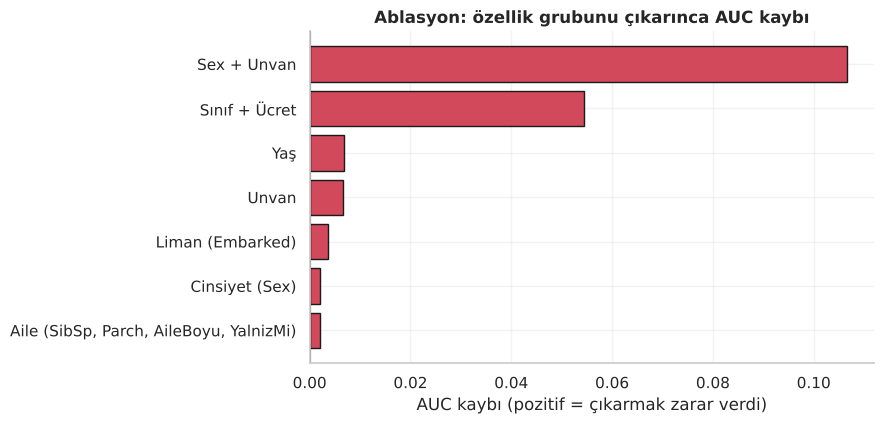

In [31]:
en_iyi_prm = {k.split("__")[1]: v for k, v in arama_lgb.best_params_.items()}
def cv_ayarli(at=None, cv=CV_TAZE):
    m = lgb_dogal(MANIFEST, tut=SECILI, at=at, verbosity=-1, random_state=R, n_jobs=1, subsample_freq=1, **en_iyi_prm)
    r = cross_validate(m, Xtr, ytr, cv=cv, scoring=SK4, n_jobs=4)
    return {"AUC": r["test_auc"].mean(), "Log-loss": -r["test_ll"].mean(), "Doğruluk": r["test_acc"].mean()}
gruplar_ab = {"Hiçbiri (tam model)": [], "Cinsiyet (Sex)": ["Sex"], "Unvan": ["Unvan"], "Sex + Unvan": ["Sex", "Unvan"], "Sınıf + Ücret": ["Pclass", "Fare", "KisiBasiUcret"],
              "Yaş": ["Age", "YasEksik"], "Aile (SibSp, Parch, AileBoyu, YalnizMi)": ["SibSp", "Parch", "AileBoyu", "YalnizMi"], "Liman (Embarked)": ["Embarked"]}
ab = pd.DataFrame({ad: cv_ayarli(at=k) for ad, k in gruplar_ab.items()}).T
ab["AUC kaybı"] = ab.loc["Hiçbiri (tam model)", "AUC"] - ab["AUC"]; display(ab.round(4)); rapor_kaydet(ab, "20_ablasyon")
fig, ax = plt.subplots(figsize=(9, 4.4)); a2 = ab.drop(index="Hiçbiri (tam model)").sort_values("AUC kaybı")
ax.barh(a2.index, a2["AUC kaybı"], color=[RENK["pembe"] if v > 0 else RENK["yesil"] for v in a2["AUC kaybı"]], edgecolor="k"); ax.axvline(0, color="k")
ax.set(title="Ablasyon: özellik grubunu çıkarınca AUC kaybı", xlabel="AUC kaybı (pozitif = çıkarmak zarar verdi)"); plt.tight_layout(); kaydet(fig, "19_ablasyon"); plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Dört ölçü **aynı sıralamayı vermiyor**: *split* sayısı sürekli sütunları (`Age`, `Fare`) kayırır; *gain* ve *SHAP* `Sex` ve `Unvan`'ı öne çıkarır; *permütasyon* ise `Pclass`'ı. `Sex` ile `Unvan` aynı bilgiyi paylaştığı için biri çıkarıldığında diğeri açığı kapatır; ablasyon tablosu bunu **tek tek ve birlikte** çıkararak gösterir. Hangi ölçüye güvendiğinize karar vermeden önce **ablasyona** bakın.

</td></tr></table>

<a id="p12"></a>

<p align="center">
  <img src="assets/proje_12.svg" width="100%" alt="Bölüm 12 · Final model">
</p>

### 🔓 12.1 · Test Seti Açılıyor (Tek Seferlik)

Tüm seçimler (özellik kümesi, algoritma ailesi, hiperparametre) **eğitim kısmında ve gruplu katlarda** yapıldı. Test setine ilk kez şimdi bakıyoruz. İki görünüm:

- **Tüm test (179 yolcu):** standart rastgele ayrım
- **Hiç görülmemiş bilet grupları:** bileti eğitimdeki hiç kimseyle paylaşmayan test yolcuları (gerçek kullanım koşuluna daha yakın)

,n,Doğruluk,F1 (kurtuldu),ROC-AUC,Log-loss,Brier
Tüm test,179.0,0.8212,0.7419,0.8563,0.4440,0.1376
Görülmemiş bilet grupları,112.0,0.8304,0.6885,0.8166,0.4414,0.1355
Kural: kadınsa kurtulur (tüm test),179.0,0.7765,0.6923,0.7534,NaN,0.2235


📄 Rapor → outputs/reports/21_final_test.csv


Test doğruluğu 0.821  (bootstrap %95: 0.760 – 0.877)
Test ROC-AUC   0.856  (bootstrap %95: 0.789 – 0.915)

               precision    recall  f1-score   support

 kurtulamadı      0.815     0.918     0.863       110
    kurtuldu      0.836     0.667     0.742        69

    accuracy                          0.821       179
   macro avg      0.825     0.792     0.803       179
weighted avg      0.823     0.821     0.816       179



💾 Kaydedildi → outputs/figures/20_final_test.png


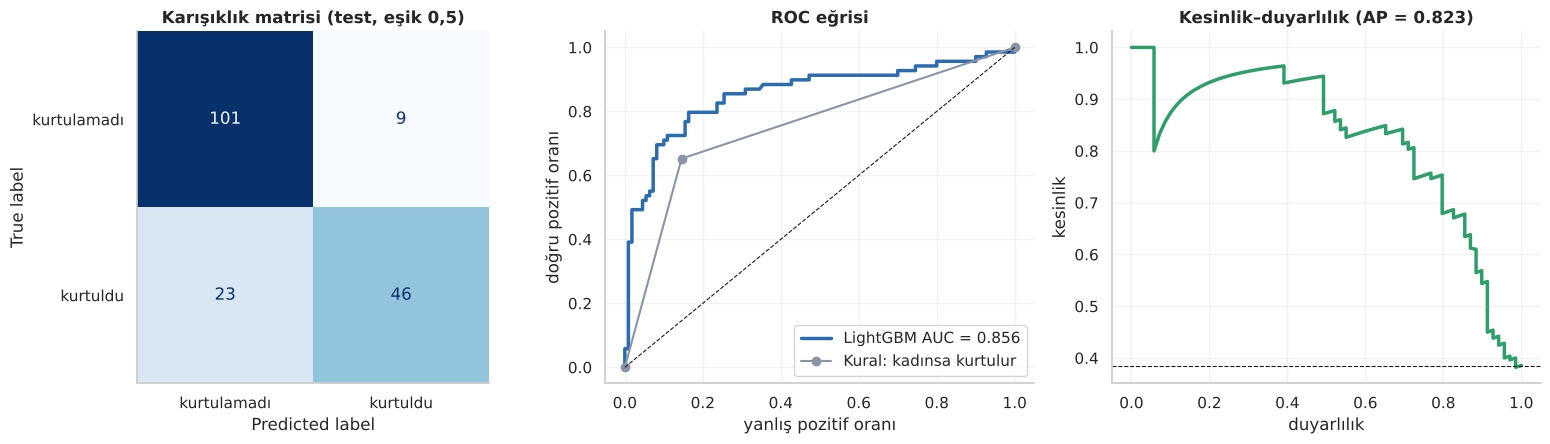

In [32]:
p_te = LGB_AYARLI.predict_proba(Xte)[:, 1]
gormemis = ~Xte["Ticket"].isin(set(Xtr["Ticket"])).to_numpy()
def metrikler(y, p, esik=0.5):
    return {"n": len(y), "Doğruluk": accuracy_score(y, p > esik), "F1 (kurtuldu)": f1_score(y, p > esik), "ROC-AUC": roc_auc_score(y, p), "Log-loss": log_loss(y, p), "Brier": brier_score_loss(y, p)}
final_tablo = pd.DataFrame({"Tüm test": metrikler(yte, p_te), "Görülmemiş bilet grupları": metrikler(yte[gormemis], p_te[gormemis])}).T
kural_te = (Xte["Sex"] == "female").astype(int).to_numpy()
final_tablo.loc["Kural: kadınsa kurtulur (tüm test)"] = {"n": len(yte), "Doğruluk": accuracy_score(yte, kural_te), "F1 (kurtuldu)": f1_score(yte, kural_te), "ROC-AUC": roc_auc_score(yte, kural_te), "Log-loss": np.nan, "Brier": brier_score_loss(yte, kural_te)}
display(final_tablo.round(4)); rapor_kaydet(final_tablo, "21_final_test")

rng = np.random.default_rng(R); bi = rng.integers(0, len(yte), (2000, len(yte)))
ba = [accuracy_score(yte[i], p_te[i] > .5) for i in bi]; bu = [roc_auc_score(yte[i], p_te[i]) for i in bi if len(np.unique(yte[i])) > 1]
print(f"Test doğruluğu {accuracy_score(yte, p_te > .5):.3f}  (bootstrap %95: {np.percentile(ba, 2.5):.3f} – {np.percentile(ba, 97.5):.3f})")
print(f"Test ROC-AUC   {roc_auc_score(yte, p_te):.3f}  (bootstrap %95: {np.percentile(bu, 2.5):.3f} – {np.percentile(bu, 97.5):.3f})")
print("\n", classification_report(yte, p_te > .5, target_names=["kurtulamadı", "kurtuldu"], digits=3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
ConfusionMatrixDisplay(confusion_matrix(yte, p_te > .5), display_labels=["kurtulamadı", "kurtuldu"]).plot(ax=ax[0], cmap="Blues", colorbar=False); ax[0].set(title="Karışıklık matrisi (test, eşik 0,5)"); ax[0].grid(False)
fpr, tpr, _ = roc_curve(yte, p_te); ax[1].plot(fpr, tpr, color=RENK["mavi"], lw=2.5, label=f"LightGBM AUC = {roc_auc_score(yte, p_te):.3f}")
fk, tk, _ = roc_curve(yte, kural_te); ax[1].plot(fk, tk, "o-", color=RENK["gri"], label="Kural: kadınsa kurtulur"); ax[1].plot([0, 1], [0, 1], "k--", lw=0.8); ax[1].legend(); ax[1].set(title="ROC eğrisi", xlabel="yanlış pozitif oranı", ylabel="doğru pozitif oranı")
pr, rc, _ = precision_recall_curve(yte, p_te); ax[2].plot(rc, pr, color=RENK["yesil"], lw=2.5); ax[2].axhline(yte.mean(), color="k", ls="--", lw=0.8)
ax[2].set(title=f"Kesinlik–duyarlılık (AP = {average_precision_score(yte, p_te):.3f})", xlabel="duyarlılık", ylabel="kesinlik")
plt.tight_layout(); kaydet(fig, "20_final_test"); plt.show()

### 🏆 12.2 · Yarışın Test Karnesi (yalnızca bilgi için)

Seçim zaten yapıldı; yine de yarışın üst sırasının test setinde nasıl durduğuna bakalım. Bu tablo **seçimi etkilemez**. Test yalnızca 179 yolcudur (doğruluk için %95 aralık yaklaşık ±%6), bu yüzden aşağıdaki küçük farklar **sıralama kanıtı sayılmaz**.

In [33]:
tk = {}
for a in ust[:8]:
    m = clone(yarisci[a][1]).fit(Xtr, ytr)
    sk = m.predict_proba(Xte)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(Xte)
    tk[a] = {"Test doğruluğu": accuracy_score(yte, m.predict(Xte)), "Test AUC": roc_auc_score(yte, sk), "Grup-CV AUC": yaris.loc[a, "ROC-AUC"]}
tk["LightGBM ayarlı (final)"] = {"Test doğruluğu": accuracy_score(yte, p_te > .5), "Test AUC": roc_auc_score(yte, p_te), "Grup-CV AUC": -np.nan}
tk = pd.DataFrame(tk).T; tk.loc["LightGBM ayarlı (final)", "Grup-CV AUC"] = np.nan
display(tk.round(4)); rapor_kaydet(tk, "22_test_karnesi")

,Test doğruluğu,Test AUC,Grup-CV AUC
Oylama (LR + RF + LightGBM),0.8268,0.8596,0.8735
Yığın (RF + LightGBM + LR → LR),0.8268,0.8602,0.8717
AdaBoost,0.7989,0.8481,0.8695
Rastgele orman,0.8212,0.8549,0.8692
"LightGBM (doğal kategori, hafif ayar)",0.8156,0.8391,0.8651
XGBoost,0.8156,0.8381,0.8645
Lojistik regresyon,0.8324,0.8789,0.8634
Ridge sınıflandırıcı,0.8436,0.8763,0.8626
LightGBM ayarlı (final),0.8212,0.8563,NaN


📄 Rapor → outputs/reports/22_test_karnesi.csv


### 🚨 12.3 · En Kötü Hatalar: Model "Çok Emin" Olduğu Hâlde Yanılan Yolcular

In [34]:
hata = Xte[["Name", "Pclass", "Sex", "Age", "Fare", "SibSp", "Parch"]].copy(); hata["p(kurtuldu)"] = p_te; hata["gerçek"] = yte
hata["güvenle yanlış"] = np.where(yte == 1, 1 - p_te, p_te)
en_kotu = hata.sort_values("güvenle yanlış", ascending=False).head(8)
display(en_kotu.drop(columns="güvenle yanlış").round(3)); rapor_kaydet(en_kotu, "23_en_kotu_hatalar")

,Name,Pclass,Sex,Age,Fare,SibSp,Parch,p(kurtuldu),gerçek
92,"Harris, Mr. George",2,male,62.0,10.500,0,0,0.039,1
41,"Allison, Miss. Helen Loraine",1,female,2.0,151.550,1,2,0.953,0
139,"Johannesen-Bratthammer, Mr. Bernt",3,male,NaN,8.113,0,0,0.066,1
53,"Williams, Mr. Charles Eugene",2,male,NaN,13.000,0,0,0.076,1
99,"Tornquist, Mr. William Henry",3,male,25.0,0.000,0,0,0.102,1
150,"Hedman, Mr. Oskar Arvid",3,male,27.0,6.975,0,0,0.114,1
2,"Leeni, Mr. Fahim (""Philip Zenni"")",3,male,22.0,7.225,0,0,0.127,1
112,"Andersson, Mr. August Edvard (""Wennerstrom"")",3,male,27.0,7.796,0,0,0.153,1


📄 Rapor → outputs/reports/23_en_kotu_hatalar.csv


<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

En kötü hataların çoğu **kurala uymayan** yolcular: sınıfı yüksek ama kurtulamayan erkekler ya da kurtulan 3. sınıf erkekler. Bu bireysel talihin bilgisi **sütunlarda yok**; hiçbir model bunu kapatamaz. Bu, **kalan belirsizliğin** doğal bir parçası.

</td></tr></table>

<a id="p13"></a>

<p align="center">
  <img src="assets/proje_13.svg" width="100%" alt="Bölüm 13 · Adalet ve segment denetimi">
</p>

Tek bir genel skor, **gruplar arası farkları saklar**. Modeli segmentlere bölüp **doğruluk (Wilson %95 aralığıyla; Wilson, 1927), doğru pozitif ve yanlış pozitif oranlarını** inceliyoruz. Daha büyük örneklem için **katlar dışı (OOF) tahminler** (tüm eğitim kümesi, 712 yolcu) kullanılır.

Eşit fırsat ölçütü (Hardt vd., 2016): iki grubun **doğru pozitif oranları** (kurtulan yolcuyu doğru bilme oranı) ne kadar farklı?

OOF (katlar dışı) AUC = 0.8593 | doğruluk = 0.8048


,n,Gerçek kurtulma %,Ort. tahmin %,Doğruluk,Doğr. alt,Doğr. üst,TPR (kurtulanı bilme),FPR (yanlış alarm)
Segment,,,,,,,,
Sex: female,253,74.308,73.420,0.771,0.715,0.818,0.910,0.631
Sex: male,459,18.519,19.269,0.824,0.786,0.856,0.224,0.040
Pclass: 1,171,64.912,64.297,0.772,0.703,0.828,0.784,0.250
Pclass: 2,150,44.667,44.413,0.927,0.873,0.959,0.910,0.060
Pclass: 3,391,24.297,24.968,0.772,0.728,0.811,0.442,0.122
YasGrubu: genç (13–29),249,35.341,36.227,0.799,0.745,0.844,0.682,0.137
YasGrubu: yaş bilinmiyor,137,29.197,29.815,0.818,0.744,0.873,0.625,0.103
YasGrubu: yaşlı (55+),30,23.333,29.164,0.867,0.703,0.947,0.571,0.043
YasGrubu: yetişkin (30–54),241,43.568,43.165,0.813,0.759,0.857,0.714,0.110


📄 Rapor → outputs/reports/24_segment_denetimi.csv


💾 Kaydedildi → outputs/figures/21_segment_dogrulugu.png


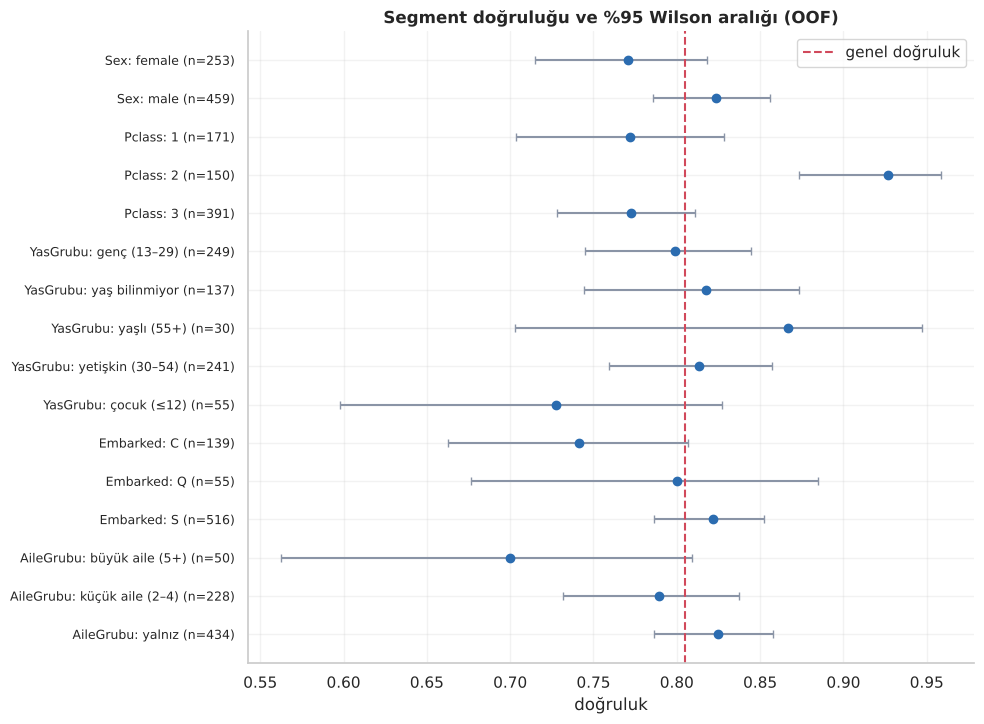

In [35]:
oof_ay = cross_val_predict(clone(LGB_AYARLI), Xtr, ytr, cv=oof_bol, method="predict_proba", n_jobs=4)[:, 1]
print(f"OOF (katlar dışı) AUC = {roc_auc_score(ytr, oof_ay):.4f} | doğruluk = {accuracy_score(ytr, oof_ay > .5):.4f}")

def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z**2 / n; m = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return m - h, m + h

D = Xtr.copy(); D["p"] = oof_ay; D["y"] = ytr
D["YasGrubu"] = pd.cut(D["Age"], [0, 12, 29, 54, 120], labels=["çocuk (≤12)", "genç (13–29)", "yetişkin (30–54)", "yaşlı (55+)"]).astype(object).fillna("yaş bilinmiyor")
D["AileGrubu"] = pd.cut(D["SibSp"] + D["Parch"] + 1, [0, 1, 4, 20], labels=["yalnız", "küçük aile (2–4)", "büyük aile (5+)"]).astype(object)
D["Unvan"] = D["Name"].map(unvan_cikar)
def segment(kol):
    s = []
    for g, d in D.groupby(kol):
        pred = d["p"] > 0.5; ok = (pred == d["y"]); pos = d["y"] == 1; neg = ~pos
        lo, hi = wilson(ok.sum(), len(d))
        s.append({"Segment": f"{kol}: {g}", "n": len(d), "Gerçek kurtulma %": 100 * d["y"].mean(), "Ort. tahmin %": 100 * d["p"].mean(), "Doğruluk": ok.mean(), "Doğr. alt": lo, "Doğr. üst": hi,
                  "TPR (kurtulanı bilme)": (pred & pos).sum() / max(pos.sum(), 1), "FPR (yanlış alarm)": (pred & neg).sum() / max(neg.sum(), 1)})
    return pd.DataFrame(s)
seg = pd.concat([segment(k) for k in ["Sex", "Pclass", "YasGrubu", "Embarked", "AileGrubu"]]).set_index("Segment")
display(seg.round(3)); rapor_kaydet(seg, "24_segment_denetimi")

fig, ax = plt.subplots(figsize=(10, 7.4)); sg = seg.iloc[::-1]
ax.errorbar(sg["Doğruluk"], range(len(sg)), xerr=[sg["Doğruluk"] - sg["Doğr. alt"], sg["Doğr. üst"] - sg["Doğruluk"]], fmt="o", color=RENK["mavi"], ecolor=RENK["gri"], capsize=3)
ax.axvline(accuracy_score(ytr, oof_ay > .5), color=RENK["pembe"], ls="--", label="genel doğruluk"); ax.set_yticks(range(len(sg))); ax.set_yticklabels([f"{i} (n={int(n)})" for i, n in zip(sg.index, sg["n"])], fontsize=9)
ax.set(title="Segment doğruluğu ve %95 Wilson aralığı (OOF)", xlabel="doğruluk"); ax.legend(); plt.tight_layout(); kaydet(fig, "21_segment_dogrulugu"); plt.show()

💾 Kaydedildi → outputs/figures/22_cinsiyet_sinif_isi.png


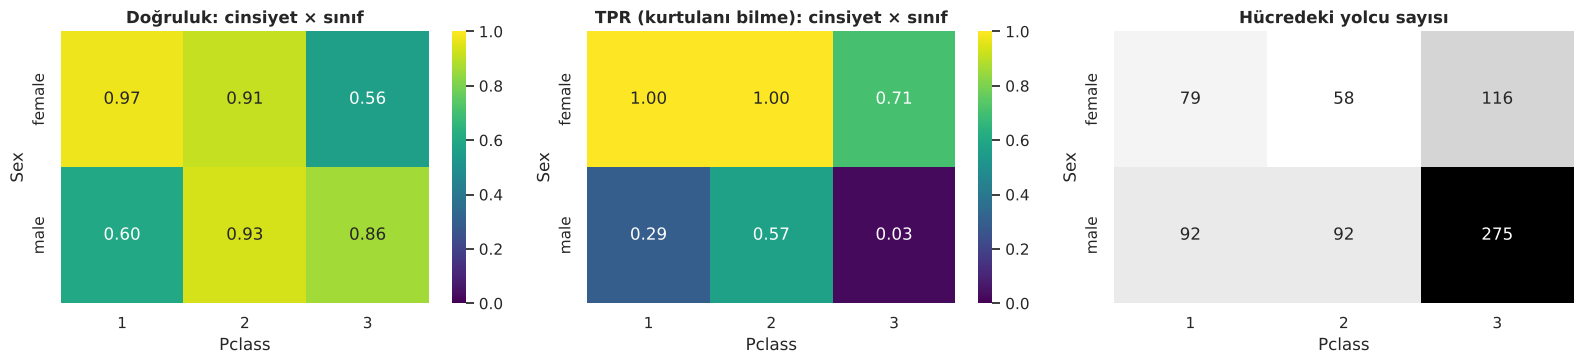

**Eşit fırsat farkı (TPR, kadın − erkek): +0.69** (kadın 0.91, erkek 0.22); FPR farkı **+0.59**. Model, **kurtulan erkekleri** kurtulan kadınlardan çok daha zor yakalıyor; çünkü erkeklerde kurtulma **nadir** ve sütunlarla ayırt etmek zor. Bu fark modelin değil **verinin tarihsel yapısının** yansımasıdır; yine de bir modeli gerçek insanlar için kullanacak olsaydık bu tabloyu **karar belgesine** koymamız şarttır.

In [36]:
# Cinsiyet × sınıf ısı haritaları: doğruluk ve doğru pozitif oranı
def hucre(d, ne):
    pred = d["p"] > 0.5; pos = d["y"] == 1
    return (pred == d["y"]).mean() if ne == "acc" else ((pred & pos).sum() / pos.sum() if pos.sum() > 0 else np.nan)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a, (ne, bs) in zip(ax[:2], [("acc", "Doğruluk"), ("tpr", "TPR (kurtulanı bilme)")]):
    t = D.groupby(["Sex", "Pclass"]).apply(lambda d: hucre(d, ne), include_groups=False).unstack(); sns.heatmap(t, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, ax=a); a.set(title=f"{bs}: cinsiyet × sınıf")
n_t = D.groupby(["Sex", "Pclass"]).size().unstack(); sns.heatmap(n_t, annot=True, fmt="d", cmap="Greys", ax=ax[2], cbar=False); ax[2].set(title="Hücredeki yolcu sayısı")
plt.tight_layout(); kaydet(fig, "22_cinsiyet_sinif_isi"); plt.show()
tpr_k = seg.loc["Sex: female", "TPR (kurtulanı bilme)"]; tpr_e = seg.loc["Sex: male", "TPR (kurtulanı bilme)"]
fpr_k = seg.loc["Sex: female", "FPR (yanlış alarm)"]; fpr_e = seg.loc["Sex: male", "FPR (yanlış alarm)"]
display(Markdown(f"**Eşit fırsat farkı (TPR, kadın − erkek): {tpr_k - tpr_e:+.2f}** (kadın {tpr_k:.2f}, erkek {tpr_e:.2f}); FPR farkı **{fpr_k - fpr_e:+.2f}**. "
                 f"Model, **kurtulan erkekleri** kurtulan kadınlardan çok daha zor yakalıyor; çünkü erkeklerde kurtulma **nadir** ve sütunlarla ayırt etmek zor. Bu fark modelin değil **verinin tarihsel yapısının** yansımasıdır; yine de bir modeli gerçek insanlar için kullanacak olsaydık bu tabloyu **karar belgesine** koymamız şarttır."))

<table><tr><td>

<img src="assets/etiket_etik.svg" height="34" alt="Etik not">

Segment tablosunda **küçük hücreler** (ör. yaşlı kadınlar, büyük aileler) geniş aralıklara sahiptir; "model bu grupta kötü" ya da "iyi" sonucuna varmadan önce **aralıklara** bakın. Tarihsel bir veriyle bugünün kararlarını eşleştirmek **geçerli bir genelleme** değildir.

</td></tr></table>

<a id="p14"></a>

<p align="center">
  <img src="assets/proje_14.svg" width="100%" alt="Bölüm 14 · Kalibrasyon ve karar">
</p>

### 🎯 14.1 · Olasılıklar Güvenilir mi?

"%80 kurtulur" dediğimiz yolcuların **gerçekte %80'i** mi kurtuluyor? Bunu **güvenilirlik (kalibrasyon) eğrisiyle** görürüz (Niculescu-Mizil ve Caruana, 2005). Sapma varsa **sigmoid** veya **isotonic** kalibrasyon denenir.

,Log-loss,Brier,ROC-AUC
Ham (ayarlı LightGBM),0.4440,0.1376,0.8563
Sigmoid kalibrasyon,0.4482,0.1405,0.8469
Isotonic kalibrasyon,0.6458,0.1425,0.8457


📄 Rapor → outputs/reports/25_kalibrasyon.csv


💾 Kaydedildi → outputs/figures/23_kalibrasyon.png


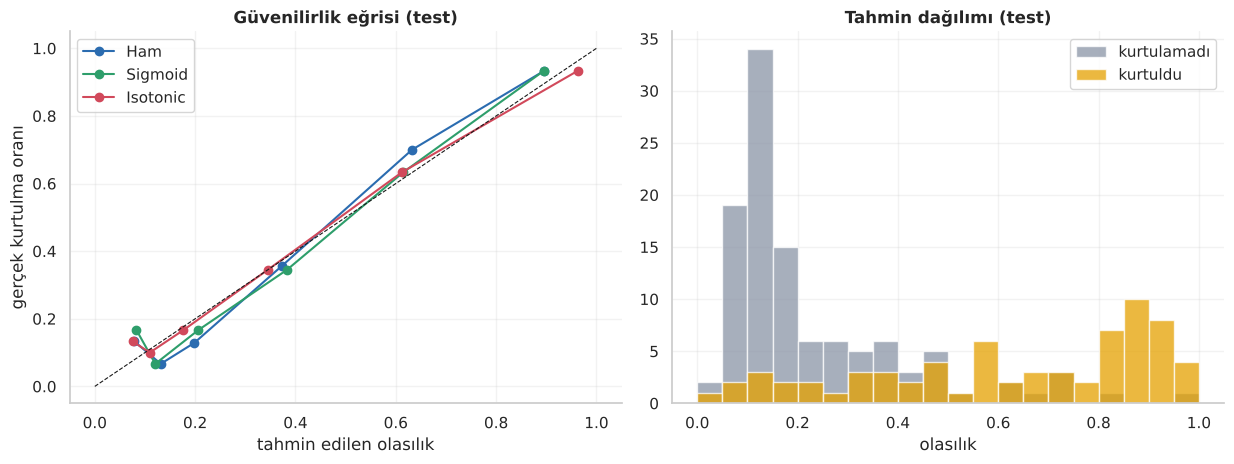

In [37]:
sig = CalibratedClassifierCV(clone(LGB_AYARLI), method="sigmoid", cv=cv_ayar).fit(Xtr, ytr)
iso = CalibratedClassifierCV(clone(LGB_AYARLI), method="isotonic", cv=cv_ayar).fit(Xtr, ytr)
p_sig, p_iso = sig.predict_proba(Xte)[:, 1], iso.predict_proba(Xte)[:, 1]
kal = pd.DataFrame({"Ham (ayarlı LightGBM)": p_te, "Sigmoid kalibrasyon": p_sig, "Isotonic kalibrasyon": p_iso}).apply(lambda p: pd.Series({"Log-loss": log_loss(yte, p), "Brier": brier_score_loss(yte, p), "ROC-AUC": roc_auc_score(yte, p)})).T
display(kal.round(4)); rapor_kaydet(kal, "25_kalibrasyon")
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.8))
for ad, p, c in [("Ham", p_te, RENK["mavi"]), ("Sigmoid", p_sig, RENK["yesil"]), ("Isotonic", p_iso, RENK["pembe"])]:
    f, m = calibration_curve(yte, p, n_bins=6, strategy="quantile"); ax[0].plot(m, f, "o-", color=c, label=ad)
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].legend(); ax[0].set(title="Güvenilirlik eğrisi (test)", xlabel="tahmin edilen olasılık", ylabel="gerçek kurtulma oranı")
ax[1].hist(p_te[yte == 0], bins=np.linspace(0, 1, 21), alpha=.75, color=RENK["gri"], label="kurtulamadı"); ax[1].hist(p_te[yte == 1], bins=np.linspace(0, 1, 21), alpha=.75, color=RENK["altin"], label="kurtuldu")
ax[1].legend(); ax[1].set(title="Tahmin dağılımı (test)", xlabel="olasılık")
plt.tight_layout(); kaydet(fig, "23_kalibrasyon"); plt.show()

### 💶 14.2 · Maliyete Duyarlı Eşik ve Bütçeli Seçim

**Senaryo (tarihsel analiz, gerçek bir karar değil):** acil durum planlamasında ekip, **kurtulma olasılığı düşük** yolcuları öncelikli destek listesine alır. *"Risk"* = `1 − p`. Destek listesine **almamak** (kurtulamayacak birini kaçırmak) **3×** pahalı, **gereksiz** almak 1×.

Eşik **yalnızca OOF tahminlerinden** seçilir, sonra testte uygulanır.

,OOF maliyet/yolcu,Test maliyet/yolcu
"Eşik 0,50",0.3525,0.2793
Eşik 0.32 (maliyete duyarlı),0.2317,0.2849


📄 Rapor → outputs/reports/26_esik_maliyeti.csv


**Okuma:** maliyete duyarlı eşik OOF'ta maliyeti **+0.121** azalttı; testte ise fark **-0.006** (küçük test ve tek bir eşik seçimi gürültülüdür). Eşik, **iş maliyetine** göre seçilir; test sonucu bunu tek başına doğrulamaz veya çürütmez.

💾 Kaydedildi → outputs/figures/24_esik_maliyeti.png


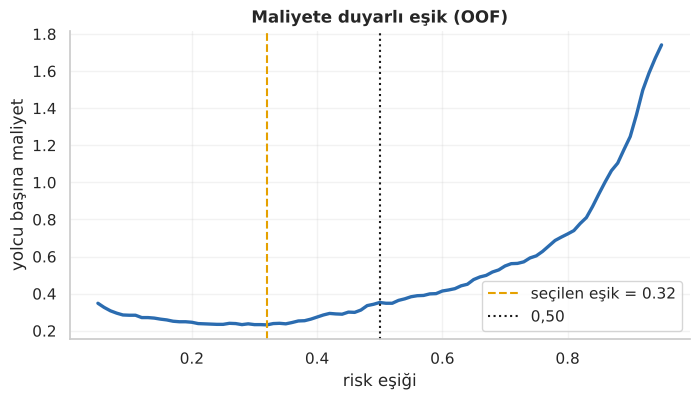

**Bütçeli seçim (K = 30):** modelin seçtiği en riskli 30 yolcudan **26'i** gerçekten kurtulamadı (kesinlik **0.87**). Rastgele 30 yolcuda beklenen kesinlik **0.61** (taban oranı 0.61); yani **lift ≈ 1.41×**. Bu 30 yolcu, test setindeki tüm kurtulamayanların **%24'ini** kapsıyor.

In [38]:
risk_oof, risk_te = 1 - oof_ay, 1 - p_te; yr_oof, yr_te = 1 - ytr, 1 - yte       # 1 = kurtulamadı (destek gerekir)
def maliyet(y_risk, risk, esik, c_fn=3.0, c_fp=1.0):
    secili = risk >= esik; fn = ((~secili) & (y_risk == 1)).sum(); fp = (secili & (y_risk == 0)).sum()
    return (c_fn * fn + c_fp * fp) / len(y_risk)
izgara = np.linspace(0.05, 0.95, 91); egri_m = [maliyet(yr_oof, risk_oof, t) for t in izgara]
t_opt = float(izgara[int(np.argmin(egri_m))])
tablo = pd.DataFrame({"Eşik 0,50": {"OOF maliyet/yolcu": maliyet(yr_oof, risk_oof, .5), "Test maliyet/yolcu": maliyet(yr_te, risk_te, .5)},
                      f"Eşik {t_opt:.2f} (maliyete duyarlı)": {"OOF maliyet/yolcu": maliyet(yr_oof, risk_oof, t_opt), "Test maliyet/yolcu": maliyet(yr_te, risk_te, t_opt)}}).T
display(tablo.round(4)); rapor_kaydet(tablo, "26_esik_maliyeti")
display(Markdown(f"**Okuma:** maliyete duyarlı eşik OOF'ta maliyeti **{tablo.iloc[0, 0] - tablo.iloc[1, 0]:+.3f}** azalttı; testte ise fark **{tablo.iloc[0, 1] - tablo.iloc[1, 1]:+.3f}** (küçük test ve tek bir eşik seçimi gürültülüdür). Eşik, **iş maliyetine** göre seçilir; test sonucu bunu tek başına doğrulamaz veya çürütmez."))
fig, ax = plt.subplots(figsize=(8, 4)); ax.plot(izgara, egri_m, color=RENK["mavi"], lw=2.4); ax.axvline(t_opt, color=RENK["altin"], ls="--", label=f"seçilen eşik = {t_opt:.2f}"); ax.axvline(.5, color="k", ls=":", label="0,50")
ax.legend(); ax.set(title="Maliyete duyarlı eşik (OOF)", xlabel="risk eşiği", ylabel="yolcu başına maliyet"); kaydet(fig, "24_esik_maliyeti"); plt.show()

# Bütçeli seçim: test setinde en riskli K yolcu
K = 30; en_riskli = np.argsort(-risk_te)[:K]
kesinlik = yr_te[en_riskli].mean(); taban = yr_te.mean(); erkek_kural = (Xte["Sex"] == "male").to_numpy()
rastgele_k = np.mean([yr_te[rng.choice(len(yte), K, replace=False)].mean() for _ in range(2000)])
display(Markdown(f"**Bütçeli seçim (K = {K}):** modelin seçtiği en riskli {K} yolcudan **{int(yr_te[en_riskli].sum())}'i** gerçekten kurtulamadı (kesinlik **{kesinlik:.2f}**). Rastgele {K} yolcuda beklenen kesinlik **{rastgele_k:.2f}** (taban oranı {taban:.2f}); yani **lift ≈ {kesinlik / rastgele_k:.2f}×**. Bu {K} yolcu, test setindeki tüm kurtulamayanların **%{100 * yr_te[en_riskli].sum() / yr_te.sum():.0f}'ini** kapsıyor."))

<a id="p15"></a>

<p align="center">
  <img src="assets/proje_15.svg" width="100%" alt="Bölüm 15 · Model kaydı">
</p>

### 💾 15.1 · Modeli Kaydet

Tüm boru hattı (özellik üretimi + kategori dönüştürücü + LightGBM) **tek dosyaya** kaydedilir. Özellik üreticileri `titanik_yardimci.py` içinde olduğu için dosya **ayrı bir süreçte** de yüklenebilir.

In [39]:
import joblib, json, subprocess
MODEL_DIR = Path("outputs/model"); MODEL_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(LGB_AYARLI, MODEL_DIR / "titanik_lightgbm.joblib")
meta = {"model": "LightGBM (ayarlı) + sızıntısız boru hattı", "ozellikler": SECILI, "en_iyi_ayar": {k: (float(v) if isinstance(v, (float, np.floating)) else (int(v) if isinstance(v, (int, np.integer)) else v)) for k, v in en_iyi_prm.items()},
        "egitim_satir": int(len(Xtr)), "test_dogruluk": round(float(accuracy_score(yte, p_te > .5)), 4), "test_auc": round(float(roc_auc_score(yte, p_te)), 4),
        "secilen_esik_maliyet": t_opt, "surumler": {"lightgbm": lgb.__version__, "scikit-learn": sklearn.__version__, "pandas": pd.__version__},
        "uyari": "Tarihsel veriyle eğitilmiş eğitim amaçlı modeldir; gerçek kişiler hakkında karar vermek için kullanılamaz."}
(MODEL_DIR / "meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
print("Kaydedildi:", [p.name for p in MODEL_DIR.iterdir()])

Kaydedildi: ['titanik_lightgbm.joblib', 'meta.json', 'ornek_yolcular.csv']


### 🧰 15.2 · Tahmin Fonksiyonu ve Ayrı Süreçte Yükleme Testi

In [40]:
def tahmin_et(yolcu, model=None):
    """Ham yolcu bilgilerinden (sözlük ya da liste) kurtulma olasılığı döndürür. Eksik alanlar boş (NaN) kabul edilir."""
    model = model or joblib.load(MODEL_DIR / "titanik_lightgbm.joblib")
    sutunlar = ["Pclass", "Name", "Sex", "Age", "SibSp", "Parch", "Ticket", "Fare", "Cabin", "Embarked"]
    df = pd.DataFrame([yolcu] if isinstance(yolcu, dict) else yolcu).reindex(columns=sutunlar)
    return model.predict_proba(df)[:, 1]

ornek = pd.DataFrame([
    {"Pclass": 3, "Name": "Ornek, Mr. Bir", "Sex": "male", "Age": 22, "SibSp": 0, "Parch": 0, "Ticket": "X1", "Fare": 7.8, "Cabin": None, "Embarked": "S"},
    {"Pclass": 1, "Name": "Ornek, Miss. Iki", "Sex": "female", "Age": 25, "SibSp": 0, "Parch": 1, "Ticket": "X2", "Fare": 120.0, "Cabin": "B58", "Embarked": "C"},
    {"Pclass": 2, "Name": "Ornek, Master. Uc", "Sex": "male", "Age": 6, "SibSp": 1, "Parch": 1, "Ticket": "X3", "Fare": 26.0, "Cabin": None, "Embarked": "S"}])
ornek.to_csv(MODEL_DIR / "ornek_yolcular.csv", index=False)
p_ici = tahmin_et(ornek)
kod = "import sys; sys.path.insert(0, '.'); import joblib, pandas as pd; m = joblib.load('outputs/model/titanik_lightgbm.joblib'); X = pd.read_csv('outputs/model/ornek_yolcular.csv'); print(' '.join(f'{v:.10f}' for v in m.predict_proba(X)[:, 1]))"
cikis = subprocess.run([sys.executable, "-I", "-c", kod], capture_output=True, text=True, cwd=".")
print("Ayrı süreç çıktısı :", cikis.stdout.strip() or cikis.stderr[-300:])
p_dis = np.array([float(v) for v in cikis.stdout.split()])
print("Süreç içi tahmin   :", " ".join(f"{v:.10f}" for v in p_ici))
print("En büyük fark      :", float(np.abs(p_ici - p_dis).max()))
display(pd.DataFrame({"Yolcu": ["genç erkek, 3. sınıf", "genç kadın, 1. sınıf", "6 yaşında erkek çocuk, 2. sınıf"], "Kurtulma olasılığı": p_ici.round(3)}))

Ayrı süreç çıktısı : 0.0938745591 0.9462409889 0.7330506032
Süreç içi tahmin   : 0.0938745591 0.9462409889 0.7330506032
En büyük fark      : 4.987718571491939e-11


,Yolcu,Kurtulma olasılığı
0,"genç erkek, 3. sınıf",0.094
1,"genç kadın, 1. sınıf",0.946
2,"6 yaşında erkek çocuk, 2. sınıf",0.733


<table><tr><td>

<img src="assets/etiket_etik.svg" height="34" alt="Etik not">

Bu fonksiyon **tarihsel bir olayın eğitim amaçlı** modelidir. Gerçek kişiler hakkında karar vermek için kullanılamaz; örnek yolcular **kurgusaldır**.

</td></tr></table>

<a id="p16"></a>

<p align="center">
  <img src="assets/proje_16.svg" width="100%" alt="Bölüm 16 · Özet">
</p>

### 📋 16.1 · Bu Projenin Sayıları

In [41]:
lider_ad = yaris.index[0]
ozet = pd.DataFrame([
    ("Algoritma sayısı (taban hariç)", alg_sayisi),
    ("Grup-CV'de en yüksek AUC (algoritma)", f"{yaris['ROC-AUC'].iloc[0]:.3f} ({lider_ad})"),
    ("LightGBM (varsayılan, ortak boru hattı) grup-CV AUC / sıra", f"{yaris.loc['LightGBM (varsayılan, ortak boru hattı)', 'ROC-AUC']:.3f} / {int(yaris.loc['LightGBM (varsayılan, ortak boru hattı)', 'Sıra (AUC)'])}."),
    ("Rastgele katlar − grup katları (doğruluk)", f"{duzen.loc['Rastgele katlar', 'Doğruluk'] - duzen.loc['Grup (bilet) katları', 'Doğruluk']:+.3f}"),
    ("Seçilen özellik kümesi", f"{len(SECILI)} özellik"),
    ("LightGBM ayarlı, taze katlarda log-loss", f"{taze2.loc['LightGBM ayarlı', 'Log-loss']:.4f} (varsayılan {taze2.loc['LightGBM varsayılan', 'Log-loss']:.4f})"),
    ("Final test doğruluğu / AUC", f"{accuracy_score(yte, p_te > .5):.3f} / {roc_auc_score(yte, p_te):.3f}"),
    ("Basit kural «kadınsa kurtulur», test doğruluğu", f"{accuracy_score(yte, kural_te):.3f}"),
    ("Görülmemiş bilet gruplarında test doğruluğu", f"{final_tablo.loc['Görülmemiş bilet grupları', 'Doğruluk']:.3f}"),
    ("Maliyete duyarlı eşik", f"{t_opt:.2f}"),
], columns=["Ölçüm", "Değer"])
display(ozet.style.hide(axis="index")); rapor_kaydet(ozet, "99_proje_ozeti", index=False)
display(Markdown("**Dürüst yorum:** Final modelin test doğruluğunu basit **«kadınsa kurtulur»** kuralıyla yan yana okuyun; üstünlük küçükse, bu verinin **bilgi tavanına** yaklaşıldığını gösterir. Üst sıradaki algoritmalar arasındaki farkların çoğu bootstrap'e göre **ayırt edilemez**; «LightGBM en iyisidir» iddiası **yapılmıyor**."))

Ölçüm,Değer
Algoritma sayısı (taban hariç),27
Grup-CV'de en yüksek AUC (algoritma),0.873 (Oylama (LR + RF + LightGBM))
"LightGBM (varsayılan, ortak boru hattı) grup-CV AUC / sıra",0.855 / 14.
Rastgele katlar − grup katları (doğruluk),+0.013
Seçilen özellik kümesi,8 özellik
"LightGBM ayarlı, taze katlarda log-loss",0.4331 (varsayılan 0.5223)
Final test doğruluğu / AUC,0.821 / 0.856
"Basit kural «kadınsa kurtulur», test doğruluğu",0.777
Görülmemiş bilet gruplarında test doğruluğu,0.830
Maliyete duyarlı eşik,0.32


📄 Rapor → outputs/reports/99_proje_ozeti.csv


**Dürüst yorum:** Final modelin test doğruluğunu basit **«kadınsa kurtulur»** kuralıyla yan yana okuyun; üstünlük küçükse, bu verinin **bilgi tavanına** yaklaşıldığını gösterir. Üst sıradaki algoritmalar arasındaki farkların çoğu bootstrap'e göre **ayırt edilemez**; «LightGBM en iyisidir» iddiası **yapılmıyor**.

<p align="center">
  <img src="assets/kapanis_proje.svg" width="100%" alt="Kapanış">
</p>

### 🧠 Akılda Kalacaklar

<table>
<tr><td width="33%" valign="top" align="center"><h3>🛡️</h3><b>Doğrulama kullanım koşuluna benzemeli</b><br><sub><i>grup katları</i></sub><br><br>Aynı bilet/aile iki tarafa dağılınca skor <b>iyimser</b> olur; grup bazlı katlar dürüst tahmin verir<br><br></td><td width="33%" valign="top" align="center"><h3>🏁</h3><b>Adil yarış</b><br><sub><i>aynı boru hattı, aynı katlar, bootstrap</i></sub><br><br>27 algoritmada üst sıra çoğunlukla <b>şanstan ayırt edilemez</b>; sıralama yeni katlarda ve düzende değişir<br><br></td><td width="33%" valign="top" align="center"><h3>🧱</h3><b>Sade özellik, güçlü model</b><br><sub><i>seçim kuralı önceden</i></sub><br><br>Her özellik kazandırmaz; küçük veride <b>az ama sağlam</b> özellik tercih edilir<br><br></td></tr>
<tr><td width="33%" valign="top" align="center"><h3>🍃</h3><b>LightGBM düğmeleri</b><br><sub><i>num_leaves · min_child_samples · λ · η</i></sub><br><br>Küçük veride <b>frenler</b> varsayılandan daha önemli; eğitim-doğrulama makası ezberi gösterir<br><br></td><td width="33%" valign="top" align="center"><h3>🔍</h3><b>Önem ≠ neden</b><br><sub><i>split · gain · permütasyon · SHAP · ablasyon</i></sub><br><br>Dört önem ölçüsü farklı konuşur; <b>ablasyon</b> gerçekten çıkarıp ölçer<br><br></td><td width="33%" valign="top" align="center"><h3>⚖️</h3><b>Adalet bir ölçüm işidir</b><br><sub><i>segment, TPR, FPR</i></sub><br><br>Genel skor grup farklarını saklar; küçük hücrelerde <b>aralıklara</b> bakın<br><br></td></tr>
</table>

### ❓ Quiz (cevaplar açılır kutularda)

<details><summary><b>1.</b> Rastgele katlar neden grup katlarından daha yüksek skor veriyor?</summary>

Aynı bileti paylaşan yolcular (aile/grup) benzer özellikler taşır. Rastgele katlarda bu üyeler hem eğitimde hem doğrulamada yer alır; model **akrabayı ezberleyerek** doğrulamada başarılı görünür. Grup katlarında aynı bilet tek tarafta kalır, skor gerçeğe yaklaşır.
</details>

<details><summary><b>2.</b> «Aynı biletteki diğer yolcuların kurtulma oranı» özelliği neden modele alınmadı?</summary>

Yeni bir yolcu listesinde akrabaların **sonuçları bilinmez**; özellik tahmin anında elde edilemez. Ayrıca doğrulama katındaki etiketlerle hesaplanırsa **sızıntı** olur.
</details>

<details><summary><b>3.</b> İki algoritmanın AUC farkının %95 bootstrap aralığı sıfırı kesiyorsa ne demektir?</summary>

Fark **şanstan ayırt edilemez**. Hangisinin «gerçekten» iyi olduğunu söyleyemeyiz; sıralama bir tahmindir, kesinlik değil.
</details>

<details><summary><b>4.</b> Eğitim log-loss düşerken doğrulama log-loss yükseliyorsa ne yapmalı?</summary>

Model ezberliyor. `num_leaves`'i küçültün, `min_child_samples`'ı artırın, λ/α ve alt örneklemeyi güçlendirin, öğrenme hızını düşürün ya da erken durdurun.
</details>

<details><summary><b>5.</b> SHAP önemi ile permütasyon önemi neden farklı sıralama verebilir?</summary>

SHAP, modelin **tahmini nasıl böldüğünü** gösterir (eğitim verisi üzerinde); permütasyon, sütunu karıştırınca **doğrulama başarısının** düşüşünü ölçer. İlişkili sütunlar (ör. `Sex` ve `Unvan`) bu ölçülerde farklı pay alabilir.
</details>

<details><summary><b>6.</b> Genel doğruluk iyiyse adalet sorunu yok mudur?</summary>

Hayır. Genel skor, gruplar arasındaki farkları saklar. Segment bazında doğruluk, TPR ve FPR bakılmalı; küçük gruplarda **aralıklar** geniştir.
</details>

### 🏠 Ödevler

1. **Özellik seçimi:** 6.2'deki seçim kuralını **AUC'ye** göre değiştirin; seçilen küme değişiyor mu? Final test skoru nasıl etkileniyor?
2. **Yeni özellik:** `Unvan` yerine yaşı unvana göre **medyanla** dolduran bir `Age` üretin (yalnızca eğitim katından öğrenerek!); grup-CV'de fark var mı?
3. **Yarışa ekleyin:** `HistGradientBoosting` için `categorical_features` kullanın ve yarışa «doğal kategori» sürümünü ekleyin.
4. **Maliyet matrisi:** 14.2'de FN maliyetini 1, 3, 10 yapın; seçilen eşik nasıl kayıyor?
5. **Adalet:** Segment denetimini `Pclass × Sex` hücrelerinde yapıp en kötü TPR'li hücreyi bulun; küçük örneklem uyarısını yazın.
6. *(Zor)* Aynı akışı **Kaggle test dosyası** ile (etiketsiz) çalıştırıp sadece tahmin üretin; üretimde hangi adımlar değişirdi?

### 📚 KAYNAKÇA

Metin içi atıflar APA 7 biçimindedir. **Dolaylı atıf**, kaynağa ikinci elden ulaşıldığında "(B, A'dan aktarma)" kalıbıyla gösterilir; bu notebook'taki örnek: *Gradyan artırma fikri (Friedman, 2001, Ke vd., 2017'den aktarma) LightGBM'de kova, GOSS ve yaprak yaprak büyüme ile hızlandırılmıştır.* Veri setinin tarihsel bağlamı için Frey vd. (2011) ve Hall (1986), doğrulama sızıntıları için Kaufman vd. (2012) ve Roberts vd. (2017), güncel kıyaslamalar için Grinsztajn vd. (2022) ile Erickson vd. (2025) esas alınmıştır.

- Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research, 13*, 281–305.
- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785–794. https://doi.org/10.1145/2939672.2939785
- Erickson, N., Purucker, L., Tschalzev, A., Holzmüller, D., Desai, P. M., Salinas, D., & Hutter, F. (2025). *TabArena: A living benchmark for machine learning on tabular data*. arXiv. https://arxiv.org/abs/2506.16791
- Frey, B. S., Savage, D. A., & Torgler, B. (2011). Behavior under extreme conditions: The Titanic disaster. *Journal of Economic Perspectives, 25*(1), 209–222. https://doi.org/10.1257/jep.25.1.209
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. https://doi.org/10.1214/aos/1013203451
- Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *Advances in Neural Information Processing Systems, 35* (Datasets and Benchmarks Track). https://arxiv.org/abs/2207.08815
- Hall, W. (1986). Social class and survival on the S.S. Titanic. *Social Science & Medicine, 22*(6), 687–690. https://doi.org/10.1016/0277-9536(86)90042-0
- Hardt, M., Price, E., & Srebro, N. (2016). Equality of opportunity in supervised learning. *Advances in Neural Information Processing Systems, 29*, 3315–3323.
- Kaggle. (2012). *Titanic: Machine learning from disaster* [Veri seti ve yarışma]. https://www.kaggle.com/c/titanic
- Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), Article 15. https://doi.org/10.1145/2382577.2382579
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*, 3146–3154.
- Lundberg, S. M., Erion, G., Chen, H., DeGrave, A., Prutkin, J. M., Nair, B., Katz, R., Himmelfarb, J., Bansal, N., & Lee, S.-I. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence, 2*(1), 56–67. https://doi.org/10.1038/s42256-019-0138-9
- Niculescu-Mizil, A., & Caruana, R. (2005). Predicting good probabilities with supervised learning. *Proceedings of the 22nd International Conference on Machine Learning*, 625–632. https://doi.org/10.1145/1102351.1102430
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V., & Gulin, A. (2018). CatBoost: Unbiased boosting with categorical features. *Advances in Neural Information Processing Systems, 31*, 6638–6648.
- Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., … Dormann, C. F. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881
- Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association, 22*(158), 209–212. https://doi.org/10.1080/01621459.1927.10502953